# Monte Carlo, risco e *hedging* no modelo de Black–Scholes
### Notebook de apoio à revisão *Processos Estocásticos e Finanças* (curso do Prof. Possani)

Este notebook é o "laboratório" da revisão em LaTeX. Todo resultado teórico importante do texto é **reproduzido numericamente**, com a explicação de **cada passo da simulação** e de **como o risco é calculado**.

**Como cada seção está organizada**

1. **Ideia**: o que queremos calcular e por quê.
2. **Passo a passo**: o algoritmo em linguagem matemática.
3. **Código**: comentado linha a linha nos pontos críticos.
4. **Gráfico**: a figura que você pode mostrar ao orientador.
5. **O que observar**: a leitura correta do resultado.

**Roteiro**

| Parte | Conteúdo | Pergunta que responde |
|---|---|---|
| 1 | Blocos de construção | Como transformar números aleatórios em preços de ações? |
| 2 | Black–Scholes como referência | Qual é a resposta exata contra a qual testamos o Monte Carlo? |
| 3 | Monte Carlo para **apreçar** | Quanto vale a opção, e com que precisão? |
| 4 | Monte Carlo para **medir risco** | Quanto posso perder (VaR, ES)? |
| 5 | Monte Carlo para **testar o hedge** | Quanto risco sobra depois do *delta hedge*? |
| 6 | Síntese | O que levar para a reunião com o orientador. |

> **A distinção mais importante do notebook**: para **apreçar** simulamos sob a medida neutra ao risco $\mathbb{Q}$ (drift $r$); para **medir risco** e **testar estratégias** simulamos sob a medida real $\mathbb{P}$ (drift $\mu$). Misturar as duas é o erro conceitual mais comum.

*Requisitos:* `numpy`, `scipy`, `matplotlib`, `pandas`. Rodar todas as células leva cerca de 1–2 minutos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm

# ---------- aparência dos gráficos ----------
plt.rcParams.update({
    "figure.figsize": (9, 4), "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.alpha": 0.25, "legend.frameon": False,
})
AZUL, LARANJA, VERDE, VERMELHO, CINZA, ROXO = "#1f4e79", "#c55a11", "#2e7d32", "#b71c1c", "#7f7f7f", "#6a1b9a"
pd.options.display.float_format = "{:,.4f}".format

def caixas(ax, dados, rotulos, **kw):
    # boxplot compatível com versões antigas e novas do matplotlib
    try:
        return ax.boxplot(dados, tick_labels=rotulos, **kw)
    except TypeError:
        return ax.boxplot(dados, labels=rotulos, **kw)

# ---------- parâmetros-base (os mesmos da revisão em LaTeX) ----------
S0    = 100.0   # preço inicial da ação
K     = 100.0   # strike
R     = 0.10    # taxa livre de risco (contínua, a.a.)
SIGMA = 0.20    # volatilidade (a.a.)
T     = 1.0     # prazo (anos)
MU    = 0.15    # drift REAL da ação (só usado sob a medida P)

SEMENTE = 2026
rng = np.random.default_rng(SEMENTE)   # gerador moderno do numpy: reprodutível
print("Parâmetros carregados.")

Parâmetros carregados.


---
# Parte 1 — Blocos de construção

Toda simulação deste notebook é feita com três ingredientes:

$$
\underbrace{Z\sim\mathcal N(0,1)}_{\text{ruído}}
\;\longrightarrow\;
\underbrace{S_{t+\delta t}=S_t\exp\!\Big(\big(m-\tfrac12\sigma^2\big)\delta t+\sigma\sqrt{\delta t}\,Z\Big)}_{\text{dinâmica do preço (MBG)}}
\;\longrightarrow\;
\underbrace{g(S)}_{\text{payoff ou P\&L}}
$$

onde o drift $m$ é $\mu$ (mundo real, $\mathbb P$) ou $r$ (mundo neutro ao risco, $\mathbb Q$).

## 1.1 Gerando o ruído: normais padrão

**Ideia.** O computador gera números *pseudoaleatórios*: uma sequência determinística que, para fins estatísticos, se comporta como i.i.d. Fixar a **semente** torna o experimento **reprodutível**, o que é indispensável num trabalho acadêmico: o orientador precisa obter os mesmos números que você.

**O que conferir.** Antes de usar o gerador, verificamos que as amostras têm média 0, variância 1, assimetria 0 e curtose 3, e que o QQ-plot fica sobre a reta.

média      = +0.0011   (teórico 0)
variância  = 0.9972    (teórico 1)
assimetria = -0.0019   (teórico 0)
curtose    = 2.9962    (teórico 3)


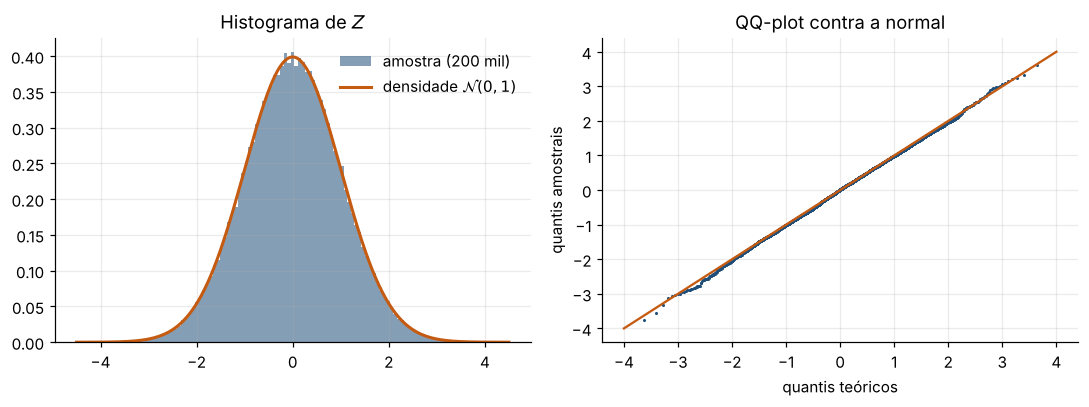

In [2]:
Z = rng.standard_normal(200_000)

print(f"média      = {Z.mean():+.4f}   (teórico 0)")
print(f"variância  = {Z.var():.4f}    (teórico 1)")
print(f"assimetria = {stats.skew(Z):+.4f}   (teórico 0)")
print(f"curtose    = {stats.kurtosis(Z, fisher=False):.4f}    (teórico 3)")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
x = np.linspace(-4.5, 4.5, 400)
ax[0].hist(Z, bins=120, density=True, color=AZUL, alpha=0.55, label="amostra (200 mil)")
ax[0].plot(x, norm.pdf(x), color=LARANJA, lw=2, label="densidade $\\mathcal{N}(0,1)$")
ax[0].set_title("Histograma de $Z$"); ax[0].legend()

(osm, osr), _ = stats.probplot(Z[:5000], dist="norm")
ax[1].plot(osm, osr, ".", ms=2, color=AZUL)
ax[1].plot([-4, 4], [-4, 4], color=LARANJA, lw=1.5)
ax[1].set_title("QQ-plot contra a normal"); ax[1].set_xlabel("quantis teóricos"); ax[1].set_ylabel("quantis amostrais")
plt.tight_layout(); plt.show()

**O que observar.** Os momentos batem com os teóricos até a terceira casa decimal, e os pontos do QQ-plot caem sobre a reta, inclusive nas caudas. Esse cuidado parece trivial, mas **VaR e ES dependem justamente das caudas**: um gerador ruim nas caudas subestimaria o risco.

## 1.2 Do ruído ao preço final $S_T$

**Ideia.** No modelo de Black–Scholes, $\mathrm dS_t = m\,S_t\,\mathrm dt+\sigma S_t\,\mathrm dW_t$, cuja solução exata (via Lema de Itô aplicado a $\ln S$) é

$$
S_T = S_0\exp\!\Big(\big(m-\tfrac12\sigma^2\big)T+\sigma\sqrt T\,Z\Big),\qquad Z\sim\mathcal N(0,1).
$$

Isso tem duas consequências práticas:

* **Para uma opção europeia não precisamos simular a trajetória inteira**: um único sorteio de $Z$ por cenário dá $S_T$ exatamente, sem erro de discretização.
* $S_T$ é **lognormal** com $\mathbb E[S_T]=S_0e^{mT}$.

**Passo a passo.**
1. Sortear $Z^{(1)},\dots,Z^{(M)}$.
2. Aplicar a fórmula acima com $m=\mu$ (para $\mathbb P$) ou $m=r$ (para $\mathbb Q$).
3. Comparar a distribuição simulada com a lognormal teórica.

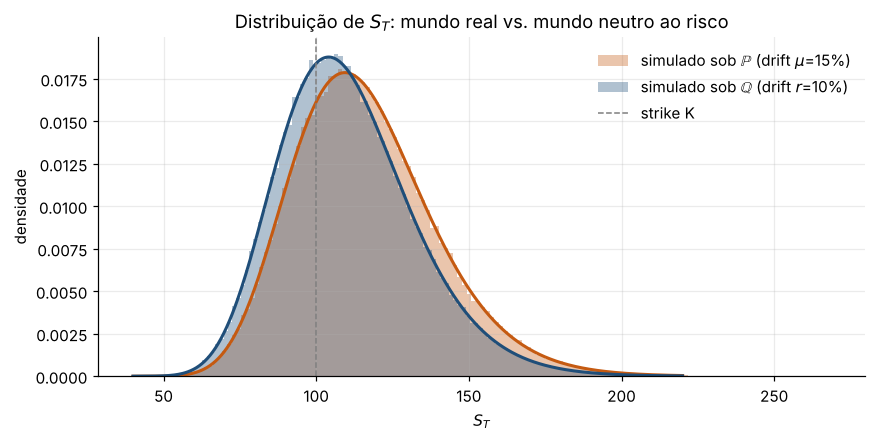

,E[S_T] simulado,E[S_T] teórico,P(S_T > K) simul.
Medida P (real),116.2025,116.1834,0.7416
Medida Q (neutra),110.4871,110.5171,0.6544


In [3]:
def simular_ST(M, drift, sigma=SIGMA, T=T, S0=S0, rng=rng):
    # Simula M valores de S_T pela solução EXATA do MBG.
    # drift = MU  -> medida real P     (usada para risco)
    # drift = R   -> medida neutra Q   (usada para apreçar)
    Z = rng.standard_normal(M)
    return S0 * np.exp((drift - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)

M = 200_000
ST_P = simular_ST(M, MU)
ST_Q = simular_ST(M, R)

def dens_lognormal(s, drift):
    # densidade teórica de S_T: ln S_T ~ N(ln S0 + (drift - sigma^2/2)T, sigma^2 T)
    m = np.log(S0) + (drift - 0.5 * SIGMA**2) * T
    return stats.lognorm.pdf(s, s=SIGMA * np.sqrt(T), scale=np.exp(m))

s = np.linspace(40, 220, 400)
fig, ax = plt.subplots()
ax.hist(ST_P, bins=150, density=True, alpha=0.35, color=LARANJA, label=f"simulado sob $\\mathbb{{P}}$ (drift $\\mu$={MU:.0%})")
ax.hist(ST_Q, bins=150, density=True, alpha=0.35, color=AZUL,    label=f"simulado sob $\\mathbb{{Q}}$ (drift $r$={R:.0%})")
ax.plot(s, dens_lognormal(s, MU), color=LARANJA, lw=2)
ax.plot(s, dens_lognormal(s, R),  color=AZUL, lw=2)
ax.axvline(K, color=CINZA, ls="--", lw=1, label="strike K")
ax.set_xlabel("$S_T$"); ax.set_ylabel("densidade"); ax.set_title("Distribuição de $S_T$: mundo real vs. mundo neutro ao risco")
ax.legend(); plt.show()

tabela = pd.DataFrame({
    "E[S_T] simulado":   [ST_P.mean(), ST_Q.mean()],
    "E[S_T] teórico":    [S0 * np.exp(MU * T), S0 * np.exp(R * T)],
    "P(S_T > K) simul.": [(ST_P > K).mean(), (ST_Q > K).mean()],
}, index=["Medida P (real)", "Medida Q (neutra)"])
tabela

**O que observar.**

* As curvas teóricas (linhas) coincidem com os histogramas: a simulação está correta.
* As duas distribuições **têm o mesmo formato** (mesma $\sigma$) e diferem apenas por um deslocamento do drift. Essa é a essência do Teorema de Girsanov: mudar de $\mathbb P$ para $\mathbb Q$ muda a média, não a volatilidade.
* A probabilidade de exercício é maior em $\mathbb P$ do que em $\mathbb Q$. Se apreçássemos sob $\mathbb P$, obteríamos um preço **maior** do que o de não arbitragem. Por isso:
  * **preço** ⇒ simular sob $\mathbb Q$;
  * **risco** (quanto posso perder de verdade) ⇒ simular sob $\mathbb P$.

## 1.3 Simulando trajetórias inteiras

**Ideia.** Para derivativos que dependem do caminho (asiáticas, barreiras) e, principalmente, **para simular o hedge dinâmico**, precisamos do preço em todas as datas de rebalanceamento. Dividimos $[0,T]$ em $n$ passos de tamanho $\delta t=T/n$ e aplicamos a solução exata **passo a passo**:

$$
\ln S_{t_{k+1}}=\ln S_{t_k}+\big(m-\tfrac12\sigma^2\big)\delta t+\sigma\sqrt{\delta t}\,Z_{k+1},\qquad Z_k \text{ i.i.d.}
$$

Em termos computacionais, sorteamos uma **matriz** $Z$ de tamanho (trajetórias × passos), multiplicamos e fazemos a **soma acumulada** (`cumsum`) ao longo do tempo. Isso é exatamente a construção do browniano como soma de incrementos gaussianos independentes.

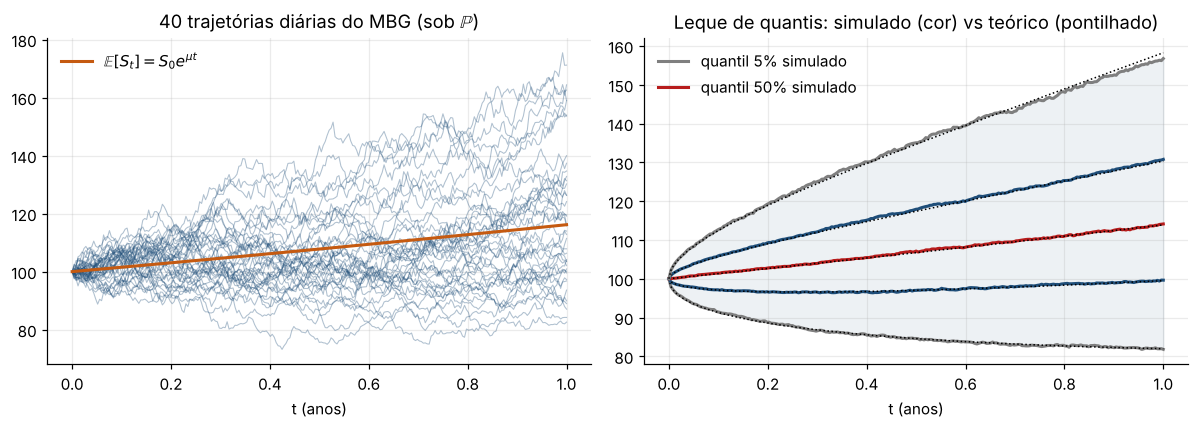

variância dos log-retornos diários: 0.000159   teórico sigma^2*dt = 0.000159
mediana de S_T simulada: 114.12   teórica S0*exp((mu-sigma^2/2)T) = 113.88


In [4]:
def simular_trajetorias(n_traj, n_passos, drift, sigma=SIGMA, T=T, S0=S0, rng=rng):
    # Retorna (t, S) com S de dimensão (n_traj, n_passos+1); a coluna 0 é S0.
    dt = T / n_passos
    Z = rng.standard_normal((n_traj, n_passos))                         # ruído
    incrementos_log = (drift - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z
    logS = np.log(S0) + np.cumsum(incrementos_log, axis=1)              # soma acumulada no tempo
    S = np.exp(np.hstack([np.full((n_traj, 1), np.log(S0)), logS]))
    t = np.linspace(0, T, n_passos + 1)
    return t, S

t, S = simular_trajetorias(5_000, 252, MU)

# quantis teóricos de S_t: S0 * exp((mu - sigma^2/2)t + sigma sqrt(t) z_q)
qs = [0.05, 0.25, 0.50, 0.75, 0.95]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(t, S[:40].T, color=AZUL, alpha=0.35, lw=0.7)
ax[0].plot(t, S0 * np.exp(MU * t), color=LARANJA, lw=2, label="$\\mathbb{E}[S_t]=S_0e^{\\mu t}$")
ax[0].set_title("40 trajetórias diárias do MBG (sob $\\mathbb{P}$)"); ax[0].set_xlabel("t (anos)"); ax[0].legend()

for q, c in zip(qs, [CINZA, AZUL, VERMELHO, AZUL, CINZA]):
    ax[1].plot(t, np.quantile(S, q, axis=0), color=c, lw=2, label=f"quantil {q:.0%} simulado" if q in (0.05, 0.5) else None)
    ax[1].plot(t, S0 * np.exp((MU - 0.5 * SIGMA**2) * t + SIGMA * np.sqrt(t) * norm.ppf(q)), "k:", lw=1)
ax[1].fill_between(t, np.quantile(S, 0.05, axis=0), np.quantile(S, 0.95, axis=0), color=AZUL, alpha=0.08)
ax[1].set_title("Leque de quantis: simulado (cor) vs teórico (pontilhado)"); ax[1].set_xlabel("t (anos)"); ax[1].legend()
plt.tight_layout(); plt.show()

# checagem: retornos logarítmicos diários devem ter variância sigma^2 * dt
r_log = np.diff(np.log(S), axis=1)
print(f"variância dos log-retornos diários: {r_log.var():.6f}   teórico sigma^2*dt = {SIGMA**2/252:.6f}")
print(f"mediana de S_T simulada: {np.median(S[:, -1]):.2f}   teórica S0*exp((mu-sigma^2/2)T) = {S0*np.exp((MU-0.5*SIGMA**2)*T):.2f}")

**O que observar.**

* O leque se abre como $\sqrt t$: a incerteza cresce com a **raiz** do tempo, uma assinatura do movimento browniano.
* A **mediana** ($\approx S_0e^{(\mu-\sigma^2/2)T}$) fica **abaixo** da média ($S_0e^{\mu T}$). Esse é o termo $-\tfrac12\sigma^2$ do Lema de Itô: a volatilidade reduz o crescimento composto típico.
* A variância dos log-retornos diários confere $\sigma^2\delta t$, confirmando a variação quadrática $[\ln S]_t=\sigma^2 t$.

### 1.3.1 E quando não há solução exata? Euler–Maruyama e Milstein

Para modelos sem fórmula fechada (Heston, CIR, volatilidade local), discretizamos a EDE diretamente:

* **Euler–Maruyama:** $S_{k+1}=S_k+\mu S_k\,\delta t+\sigma S_k\,\delta W_k$
* **Milstein:** adiciona $\tfrac12\sigma^2S_k\big[(\delta W_k)^2-\delta t\big]$

O termo extra do Milstein **é a variação quadrática** $(\mathrm dW)^2=\mathrm dt$ aparecendo outra vez. Para medir o erro, usamos o **mesmo browniano** para o esquema e para a solução exata e calculamos o **erro forte** $\mathbb E|S_T^{\text{esquema}}-S_T^{\text{exato}}|$ para vários $\delta t$. A teoria prevê erro de ordem $\delta t^{1/2}$ (Euler) e $\delta t^{1}$ (Milstein).

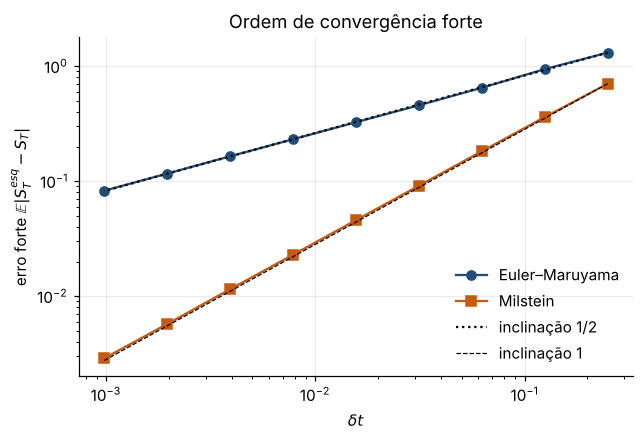

inclinação estimada Euler   : 0.499
inclinação estimada Milstein: 0.994


In [5]:
M_e, n_fino = 4_000, 2**10
dW_fino = rng.standard_normal((M_e, n_fino)) * np.sqrt(T / n_fino)      # browniano numa grade fina
S_exato = S0 * np.exp((MU - 0.5 * SIGMA**2) * T + SIGMA * dW_fino.sum(axis=1))

passos_lista, erro_euler, erro_milstein = [], [], []
for n in [2**k for k in range(2, 11)]:
    dt = T / n
    dW = dW_fino.reshape(M_e, n, n_fino // n).sum(axis=2)               # MESMO browniano, grade mais grossa
    Se = np.full(M_e, S0); Sm = np.full(M_e, S0)
    for k in range(n):
        Se = Se + MU * Se * dt + SIGMA * Se * dW[:, k]
        Sm = Sm + MU * Sm * dt + SIGMA * Sm * dW[:, k] + 0.5 * SIGMA**2 * Sm * (dW[:, k]**2 - dt)
    passos_lista.append(dt)
    erro_euler.append(np.mean(np.abs(Se - S_exato)))
    erro_milstein.append(np.mean(np.abs(Sm - S_exato)))

dts = np.array(passos_lista)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(dts, erro_euler, "o-", color=AZUL, label="Euler–Maruyama")
ax.loglog(dts, erro_milstein, "s-", color=LARANJA, label="Milstein")
ax.loglog(dts, erro_euler[0] * (dts / dts[0])**0.5, "k:", label="inclinação 1/2")
ax.loglog(dts, erro_milstein[0] * (dts / dts[0])**1.0, "k--", lw=0.8, label="inclinação 1")
ax.set_xlabel("$\\delta t$"); ax.set_ylabel("erro forte $\\mathbb{E}|S_T^{esq}-S_T|$"); ax.set_title("Ordem de convergência forte")
ax.legend(); plt.show()
print("inclinação estimada Euler   :", np.polyfit(np.log(dts), np.log(erro_euler), 1)[0].round(3))
print("inclinação estimada Milstein:", np.polyfit(np.log(dts), np.log(erro_milstein), 1)[0].round(3))

**O que observar.** As inclinações estimadas ficam próximas de 0,5 (Euler) e 1 (Milstein), como prevê a teoria. Na prática, para o MBG usamos a solução exata. O resultado mostra, porém, que **o erro de discretização é uma segunda fonte de erro**, separada do erro estatístico do Monte Carlo, que veremos na Parte 3.

---
# Parte 2 — Black–Scholes como referência

Para validar o Monte Carlo precisamos de uma resposta exata. No modelo de Black–Scholes ela existe:

$$
C=S\,N(d_1)-Ke^{-r\tau}N(d_2),\qquad d_{1}=\frac{\ln(S/K)+(r+\frac12\sigma^2)\tau}{\sigma\sqrt\tau},\quad d_2=d_1-\sigma\sqrt\tau .
$$

As **gregas** também serão usadas: o $\Delta$ define o hedge, o $\Gamma$ explica o erro do hedge, o $\Theta$ entra na aproximação delta-gama e o $\nu$ (vega) mede a sensibilidade à volatilidade.

As funções abaixo aceitam **vetores** de $S$ (um valor por cenário). Isso permite reprecificar 100 mil cenários numa única linha, sem laço.

In [6]:
def _d1_d2(S, K, r, sigma, tau):
    tau = np.maximum(tau, 1e-12)                       # evita divisão por zero no vencimento
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    return d1, d1 - sigma * np.sqrt(tau), tau

def bs_preco(S, K, r, sigma, tau, tipo="call"):
    d1, d2, tau = _d1_d2(S, K, r, sigma, tau)
    if tipo == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * tau) * norm.cdf(d2)
    return K * np.exp(-r * tau) * norm.cdf(-d2) - S * norm.cdf(-d1)

def bs_delta(S, K, r, sigma, tau, tipo="call"):
    d1, _, _ = _d1_d2(S, K, r, sigma, tau)
    return norm.cdf(d1) if tipo == "call" else norm.cdf(d1) - 1.0

def bs_gamma(S, K, r, sigma, tau):
    d1, _, tau = _d1_d2(S, K, r, sigma, tau)
    return norm.pdf(d1) / (S * sigma * np.sqrt(tau))

def bs_vega(S, K, r, sigma, tau):
    d1, _, tau = _d1_d2(S, K, r, sigma, tau)
    return S * norm.pdf(d1) * np.sqrt(tau)

def bs_theta(S, K, r, sigma, tau, tipo="call"):
    d1, d2, tau = _d1_d2(S, K, r, sigma, tau)
    termo1 = -S * norm.pdf(d1) * sigma / (2 * np.sqrt(tau))
    if tipo == "call":
        return termo1 - r * K * np.exp(-r * tau) * norm.cdf(d2)
    return termo1 + r * K * np.exp(-r * tau) * norm.cdf(-d2)

C0 = bs_preco(S0, K, R, SIGMA, T)
P0 = bs_preco(S0, K, R, SIGMA, T, "put")
D0, G0, V0, TH0 = bs_delta(S0, K, R, SIGMA, T), bs_gamma(S0, K, R, SIGMA, T), bs_vega(S0, K, R, SIGMA, T), bs_theta(S0, K, R, SIGMA, T)

print(f"Call = {C0:.4f}   Put = {P0:.4f}")
print(f"Delta = {D0:.4f}  Gamma = {G0:.4f}  Vega = {V0:.4f}  Theta = {TH0:.4f}")
# --- testes de sanidade ---
print(f"\nParidade put-call: C - P = {C0 - P0:.6f}  vs  S - K e^(-rT) = {S0 - K*np.exp(-R*T):.6f}")
h = 1e-4
print(f"Delta por diferença finita = {(bs_preco(S0+h,K,R,SIGMA,T)-bs_preco(S0-h,K,R,SIGMA,T))/(2*h):.6f}")
print(f"EDP de BS: Theta + rS·Delta + ½σ²S²·Gamma - rC = {TH0 + R*S0*D0 + 0.5*SIGMA**2*S0**2*G0 - R*C0:.2e}  (deve ser ≈ 0)")

Call = 13.2697   Put = 3.7534
Delta = 0.7257  Gamma = 0.0167  Vega = 33.3225  Theta = -9.2627

Paridade put-call: C - P = 9.516258  vs  S - K e^(-rT) = 9.516258
Delta por diferença finita = 0.725747
EDP de BS: Theta + rS·Delta + ½σ²S²·Gamma - rC = 1.78e-15  (deve ser ≈ 0)


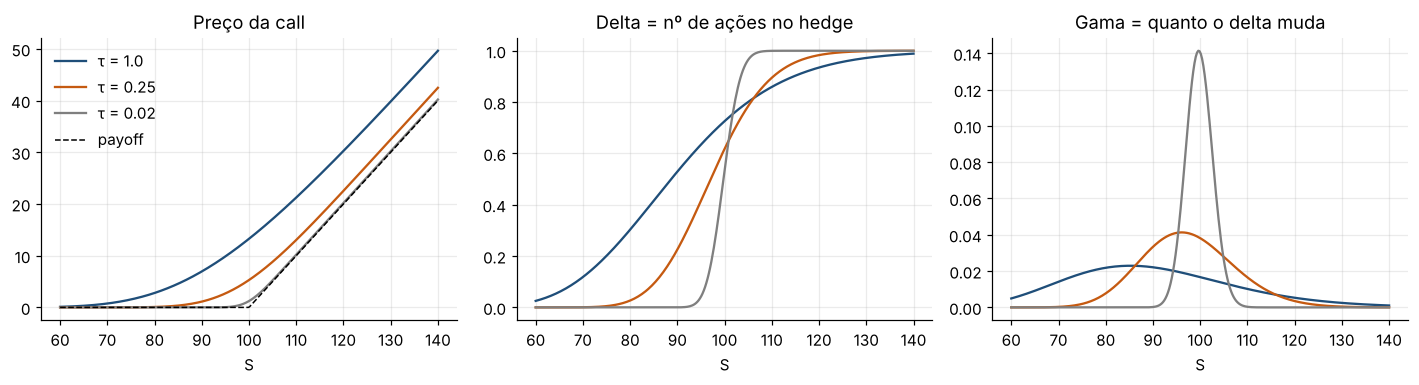

In [7]:
Sg = np.linspace(60, 140, 300)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for tau, c in [(1.0, AZUL), (0.25, LARANJA), (0.02, CINZA)]:
    ax[0].plot(Sg, bs_preco(Sg, K, R, SIGMA, tau), color=c, label=f"τ = {tau}")
    ax[1].plot(Sg, bs_delta(Sg, K, R, SIGMA, tau), color=c)
    ax[2].plot(Sg, bs_gamma(Sg, K, R, SIGMA, tau), color=c)
ax[0].plot(Sg, np.maximum(Sg - K, 0), "k--", lw=1, label="payoff")
for a, tit in zip(ax, ["Preço da call", "Delta = nº de ações no hedge", "Gama = quanto o delta muda"]):
    a.set_title(tit); a.set_xlabel("S")
ax[0].legend(); plt.tight_layout(); plt.show()

**O que observar.** Perto do vencimento ($\tau$ pequeno), o delta vira um degrau e o gama forma um pico no strike. **O hedge fica mais difícil justamente quando a opção está no dinheiro e próxima do vencimento**: pequenos movimentos de $S$ exigem grandes ajustes na quantidade de ações. Esse efeito reaparece na Parte 5.

---
# Parte 3 — Monte Carlo para **apreçar**

Pelo teorema fundamental (Feynman–Kac), o preço é uma esperança sob $\mathbb Q$:

$$
C_0=e^{-rT}\,\mathbb E^{\mathbb Q}\big[(S_T-K)^+\big].
$$

O Monte Carlo troca a esperança por uma média amostral (Lei dos Grandes Números) e usa o Teorema Central do Limite para medir o erro:

$$
\hat C_M=\frac1M\sum_{i=1}^{M}\underbrace{e^{-rT}\big(S_T^{(i)}-K\big)^+}_{Y_i},\qquad
\text{EP}=\frac{\hat s_Y}{\sqrt M},\qquad
\text{IC}_{95\%}=\hat C_M\pm1{,}96\,\text{EP}.
$$

## 3.1 O algoritmo, cenário por cenário

Para entender *exatamente* o que o computador faz, primeiro executamos o algoritmo com apenas **8 cenários** e olhamos cada número:

1. sortear $Z_i$;
2. calcular $S_T^{(i)}$ **sob $\mathbb Q$** (drift $r$);
3. calcular o payoff $(S_T^{(i)}-K)^+$;
4. descontar: $Y_i=e^{-rT}\times\text{payoff}$;
5. tirar a média e o erro-padrão.

In [8]:
rng_demo = np.random.default_rng(1)
M = 8
Z = rng_demo.standard_normal(M)                                              # passo 1
ST = S0 * np.exp((R - 0.5 * SIGMA**2) * T + SIGMA * np.sqrt(T) * Z)          # passo 2 (drift r!)
payoff = np.maximum(ST - K, 0)                                                # passo 3
Y = np.exp(-R * T) * payoff                                                   # passo 4

demo = pd.DataFrame({"Z": Z, "S_T": ST, "payoff (S_T-K)+": payoff, "Y = e^{-rT}·payoff": Y})
demo.index = [f"cenário {i+1}" for i in range(M)]
display(demo)

media, ep = Y.mean(), Y.std(ddof=1) / np.sqrt(M)                              # passo 5
print(f"Estimativa MC com {M} cenários: {media:.4f} ± {1.96*ep:.4f}   (Black–Scholes: {C0:.4f})")

,Z,S_T,payoff (S_T-K)+,Y = e^{-rT}·payoff
cenário 1,0.3456,116.0809,16.0809,14.5506
cenário 2,0.8216,127.6757,27.6757,25.0421
cenário 3,0.3304,115.7297,15.7297,14.2329
cenário 4,-1.3032,83.4743,0.0000,0.0000
cenário 5,0.9054,129.8320,29.8320,26.9931
cenário 6,0.4464,118.4446,18.4446,16.6893
cenário 7,-0.5370,97.2981,0.0000,0.0000
cenário 8,0.5811,121.6799,21.6799,19.6168


Estimativa MC com 8 cenários: 14.6406 ± 7.0211   (Black–Scholes: 13.2697)


**O que observar.** Com 8 cenários o intervalo de confiança é enorme. Note também que vários cenários têm payoff **zero** (a opção termina fora do dinheiro) enquanto outros têm payoff alto. Essa mistura de zeros com valores grandes é o que torna a variância de $Y$ alta e faz o Monte Carlo precisar de muitos cenários.

## 3.2 Agora com muitos cenários

MC (M = 200 mil): 13.2888   EP = 0.0361   IC95% = [13.2180, 13.3596]
Black–Scholes   : 13.2697   -> erro = +0.0191  (+0.53 erros-padrão)
fração de cenários com payoff zero: 34.4%


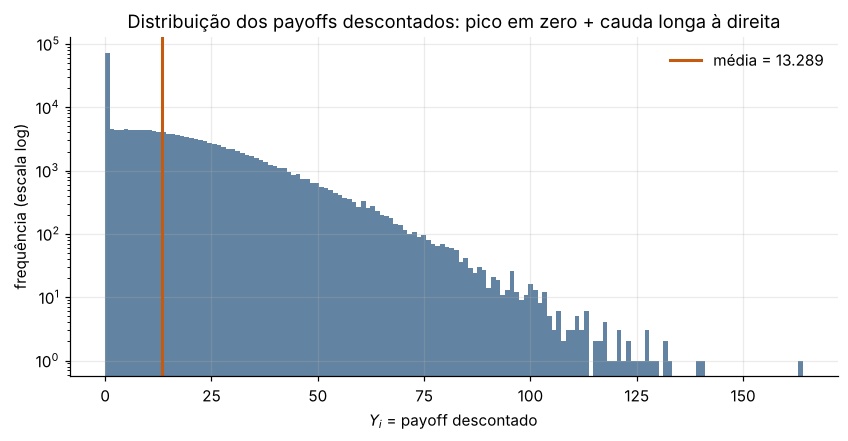

In [9]:
def mc_call(M, rng=rng, K=K, sigma=SIGMA, T=T, S0=S0, r=R):
    # Monte Carlo simples sob Q. Retorna (estimativa, erro-padrão, amostras Y).
    Z = rng.standard_normal(M)
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    Y = np.exp(-r * T) * np.maximum(ST - K, 0)
    return Y.mean(), Y.std(ddof=1) / np.sqrt(M), Y

est, ep, Y = mc_call(200_000)
print(f"MC (M = 200 mil): {est:.4f}   EP = {ep:.4f}   IC95% = [{est-1.96*ep:.4f}, {est+1.96*ep:.4f}]")
print(f"Black–Scholes   : {C0:.4f}   -> erro = {est - C0:+.4f}  ({(est - C0)/ep:+.2f} erros-padrão)")
print(f"fração de cenários com payoff zero: {(Y == 0).mean():.1%}")

fig, ax = plt.subplots()
ax.hist(Y, bins=150, color=AZUL, alpha=0.7)
ax.axvline(est, color=LARANJA, lw=2, label=f"média = {est:.3f}")
ax.set_yscale("log"); ax.set_xlabel("$Y_i$ = payoff descontado"); ax.set_ylabel("frequência (escala log)")
ax.set_title("Distribuição dos payoffs descontados: pico em zero + cauda longa à direita"); ax.legend()
plt.show()

**O que observar.** O erro em relação ao valor exato deve ficar dentro de $\pm 2$ erros-padrão, e é isso que significa uma estimativa "correta" em Monte Carlo. O resultado nunca é exato: **o erro-padrão faz parte da resposta** e deve sempre ser reportado.

## 3.3 Convergência: o erro cai como $1/\sqrt M$

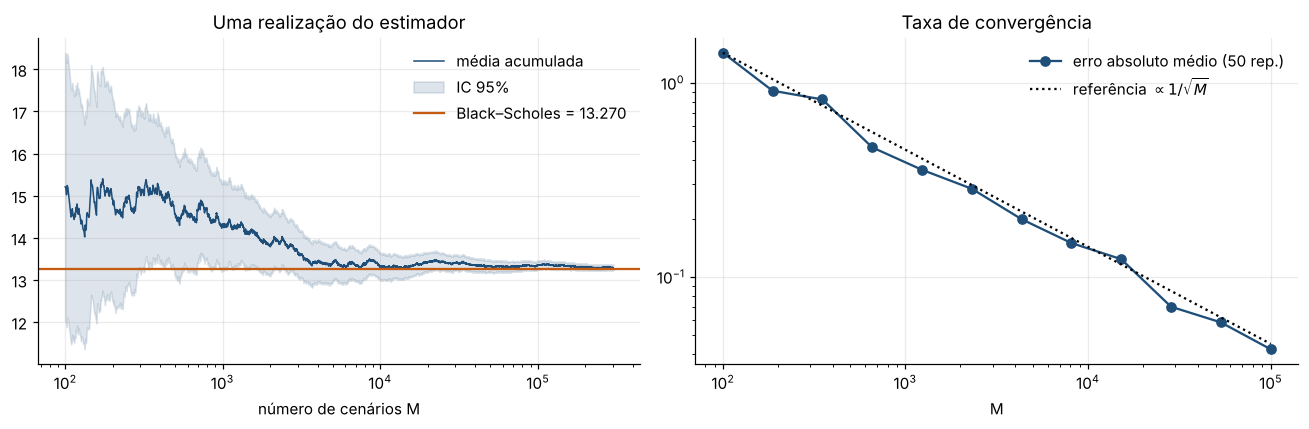

inclinação estimada: -0.502 (teoria: -0,5)


In [10]:
# (a) uma única sequência longa: média acumulada e banda de confiança
_, _, Y_long = mc_call(300_000)
n = np.arange(1, len(Y_long) + 1)
media_acum = np.cumsum(Y_long) / n
var_acum = (np.cumsum(Y_long**2) - n * media_acum**2) / np.maximum(n - 1, 1)
ep_acum = np.sqrt(var_acum / n)

# (b) erro absoluto médio em 50 repetições independentes para cada M
Ms = np.unique(np.logspace(2, 5, 12).astype(int))
erro_abs = [np.mean([abs(mc_call(m)[0] - C0) for _ in range(50)]) for m in Ms]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
idx = slice(99, None)
ax[0].semilogx(n[idx], media_acum[idx], color=AZUL, lw=1, label="média acumulada")
ax[0].fill_between(n[idx], (media_acum - 1.96 * ep_acum)[idx], (media_acum + 1.96 * ep_acum)[idx], color=AZUL, alpha=0.15, label="IC 95%")
ax[0].axhline(C0, color=LARANJA, lw=1.5, label=f"Black–Scholes = {C0:.3f}")
ax[0].set_xlabel("número de cenários M"); ax[0].set_title("Uma realização do estimador"); ax[0].legend()

ax[1].loglog(Ms, erro_abs, "o-", color=AZUL, label="erro absoluto médio (50 rep.)")
ax[1].loglog(Ms, erro_abs[0] * np.sqrt(Ms[0] / Ms), "k:", label="referência $\\propto 1/\\sqrt{M}$")
ax[1].set_xlabel("M"); ax[1].set_title("Taxa de convergência"); ax[1].legend()
plt.tight_layout(); plt.show()
print("inclinação estimada:", np.polyfit(np.log(Ms), np.log(erro_abs), 1)[0].round(3), "(teoria: -0,5)")

**O que observar.** A inclinação $-1/2$ no gráfico log-log é o TCL em ação. A consequência prática pesa: **para ganhar uma casa decimal de precisão é preciso multiplicar o número de cenários por 100**. Por isso as técnicas de redução de variância (Seção 3.5) são tão importantes.

## 3.4 O intervalo de confiança "funciona"? Teste de cobertura

Um IC de 95% deve conter o valor verdadeiro em 95% das repetições do experimento. Testamos isso diretamente: repetimos o Monte Carlo 1000 vezes (com $M=1000$ em cada) e contamos quantos intervalos contêm o preço de Black–Scholes.

cobertura empírica: 94.8%  (nominal 95%)


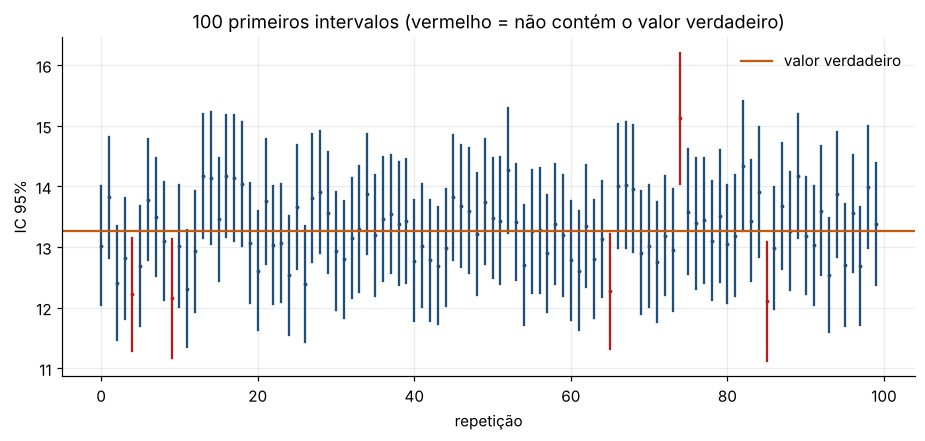

In [11]:
n_rep, M = 1000, 1000
ests, eps_ = np.empty(n_rep), np.empty(n_rep)
for i in range(n_rep):
    ests[i], eps_[i], _ = mc_call(M)
li, ls = ests - 1.96 * eps_, ests + 1.96 * eps_
cobre = (li <= C0) & (C0 <= ls)
print(f"cobertura empírica: {cobre.mean():.1%}  (nominal 95%)")

fig, ax = plt.subplots(figsize=(10, 4))
for i in range(100):
    ax.plot([i, i], [li[i], ls[i]], color=AZUL if cobre[i] else VERMELHO, lw=1.5)
    ax.plot(i, ests[i], ".", color=AZUL if cobre[i] else VERMELHO, ms=3)
ax.axhline(C0, color=LARANJA, lw=1.5, label="valor verdadeiro")
ax.set_xlabel("repetição"); ax.set_ylabel("IC 95%"); ax.set_title("100 primeiros intervalos (vermelho = não contém o valor verdadeiro)")
ax.legend(); plt.show()

**O que observar.** Cerca de 5% dos intervalos (em vermelho) erram, como esperado. Isso valida a interpretação **frequentista** do IC: o intervalo é que é aleatório, não o preço.

## 3.5 Redução de variância

Como o erro é $\sigma_Y/\sqrt M$, há duas maneiras de reduzi-lo: aumentar $M$ (caro) ou **reduzir $\sigma_Y$** (barato).

**Variáveis antitéticas.** Para cada $Z$ usamos também $-Z$ e fazemos a média $\tfrac12[Y(Z)+Y(-Z)]$. Como o payoff é crescente em $Z$, $Y(Z)$ e $Y(-Z)$ são **negativamente correlacionados**, e $\operatorname{Var}\big(\tfrac{Y(Z)+Y(-Z)}2\big)=\tfrac12\operatorname{Var}(Y)(1+\rho)<\tfrac12\operatorname{Var}(Y)$.

**Variável de controle.** Usamos uma variável $X$ correlacionada com $Y$ cuja média é **conhecida**. Aqui, $X=e^{-rT}S_T$, cuja média sob $\mathbb Q$ é exatamente $S_0$ (o preço descontado é martingal!). O estimador é

$$
Y^{\text{cv}}=Y-b\,(X-S_0),\qquad b^*=\frac{\operatorname{Cov}(Y,X)}{\operatorname{Var}(X)},\qquad \operatorname{Var}(Y^{\text{cv}})=(1-\rho_{XY}^2)\operatorname{Var}(Y).
$$

A intuição: se nesta amostra $X$ saiu acima da média verdadeira, $Y$ provavelmente também saiu, e corrigimos para baixo.

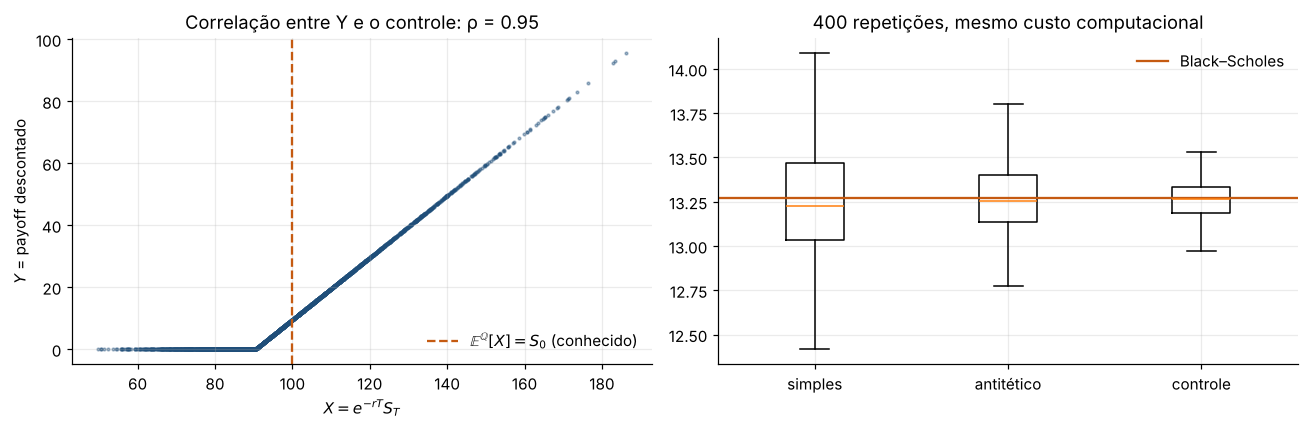

,média,desvio-padrão,fator de redução da variância,equivale a MC simples com M =
simples,13.2629,0.3687,1.0000,2000
antitético,13.2663,0.2024,3.3194,6638
controle,13.2598,0.1116,10.9176,21835


In [12]:
def mc_call_vr(M, metodo, rng=rng):
    Z = rng.standard_normal(M)
    ST = S0 * np.exp((R - 0.5 * SIGMA**2) * T + SIGMA * np.sqrt(T) * Z)
    Y = np.exp(-R * T) * np.maximum(ST - K, 0)
    if metodo == "simples":
        pass
    elif metodo == "antitético":
        ST_anti = S0 * np.exp((R - 0.5 * SIGMA**2) * T - SIGMA * np.sqrt(T) * Z)   # usa -Z
        Y = 0.5 * (Y + np.exp(-R * T) * np.maximum(ST_anti - K, 0))
    elif metodo == "controle":
        X = np.exp(-R * T) * ST                            # média conhecida = S0
        b = np.cov(Y, X)[0, 1] / np.var(X, ddof=1)         # coeficiente ótimo estimado
        Y = Y - b * (X - S0)
    return Y.mean()

# Gráfico da intuição da variável de controle
Zc = rng.standard_normal(3000)
STc = S0 * np.exp((R - 0.5 * SIGMA**2) * T + SIGMA * np.sqrt(T) * Zc)
Yc, Xc = np.exp(-R * T) * np.maximum(STc - K, 0), np.exp(-R * T) * STc
rho_xy = np.corrcoef(Yc, Xc)[0, 1]

# 400 repetições de cada estimador com M = 2000 (antitético usa M/2 pares para comparar com o mesmo custo)
n_rep, M = 400, 2000
res = {
    "simples":    [mc_call_vr(M, "simples") for _ in range(n_rep)],
    "antitético": [mc_call_vr(M // 2, "antitético") for _ in range(n_rep)],
    "controle":   [mc_call_vr(M, "controle") for _ in range(n_rep)],
}

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(Xc, Yc, s=3, alpha=0.4, color=AZUL)
ax[0].axvline(S0, color=LARANJA, ls="--", label="$\\mathbb{E}^{\\mathbb{Q}}[X]=S_0$ (conhecido)")
ax[0].set_xlabel("$X=e^{-rT}S_T$"); ax[0].set_ylabel("$Y$ = payoff descontado")
ax[0].set_title(f"Correlação entre Y e o controle: ρ = {rho_xy:.2f}"); ax[0].legend()

caixas(ax[1], list(res.values()), list(res.keys()), showfliers=False)
ax[1].axhline(C0, color=LARANJA, lw=1.5, label="Black–Scholes")
ax[1].set_title(f"{n_rep} repetições, mesmo custo computacional"); ax[1].legend()
plt.tight_layout(); plt.show()

dp_simples = np.std(res["simples"])
pd.DataFrame({
    "média": {k: np.mean(v) for k, v in res.items()},
    "desvio-padrão": {k: np.std(v) for k, v in res.items()},
    "fator de redução da variância": {k: (dp_simples / np.std(v))**2 for k, v in res.items()},
}).assign(**{"equivale a MC simples com M =": lambda d: (d["fator de redução da variância"] * M).astype(int)})

**O que observar.** A variável de controle reduz a variância por um fator próximo de $1/(1-\rho^2)$. Com o mesmo esforço computacional, **ela equivale a rodar várias vezes mais cenários**. Em bancos, onde o mesmo cálculo é feito milhares de vezes por dia, isso se traduz diretamente em economia de tempo de máquina.

## 3.6 Onde o Monte Carlo é indispensável: opção asiática

A call **asiática aritmética** paga $(\bar S-K)^+$, onde $\bar S$ é a média dos preços diários. **Não há fórmula fechada** e o payoff depende da trajetória inteira, então simulamos trajetórias completas sob $\mathbb Q$ (Seção 1.3).

Asiática : 7.0449 ± 0.0835
Europeia : 13.1758 ± 0.1566
(Europeia exata por BS: 13.2697)


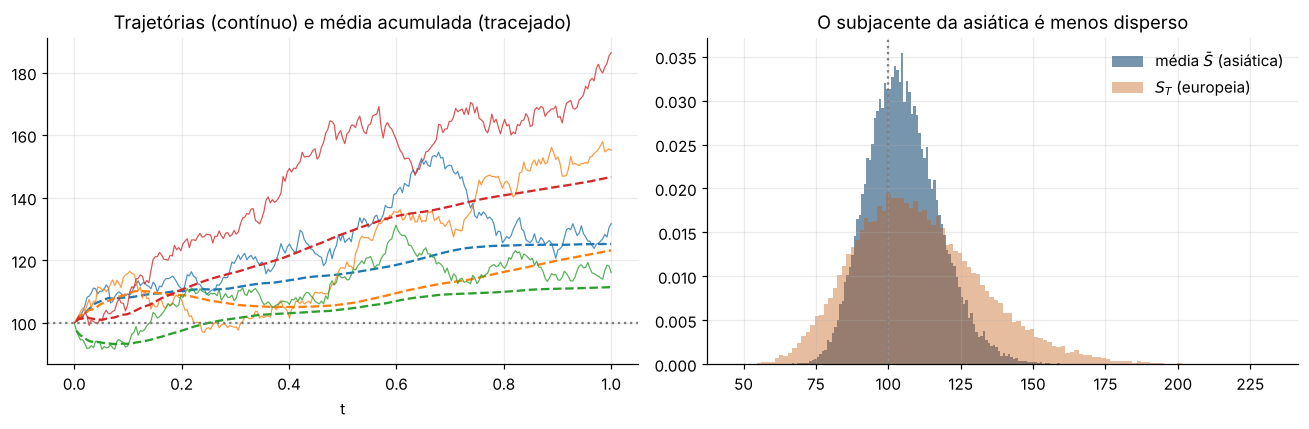

In [13]:
M_a = 40_000
t_a, S_a = simular_trajetorias(M_a, 252, drift=R)       # sob Q!
media_traj = S_a[:, 1:].mean(axis=1)                    # média aritmética dos preços diários
Y_asia = np.exp(-R * T) * np.maximum(media_traj - K, 0)
Y_euro = np.exp(-R * T) * np.maximum(S_a[:, -1] - K, 0) # europeia nas MESMAS trajetórias

for nome, Yv in [("Asiática", Y_asia), ("Europeia", Y_euro)]:
    print(f"{nome:9s}: {Yv.mean():.4f} ± {1.96*Yv.std(ddof=1)/np.sqrt(M_a):.4f}")
print(f"(Europeia exata por BS: {C0:.4f})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i in range(4):
    l, = ax[0].plot(t_a, S_a[i], lw=0.8, alpha=0.8)
    ax[0].plot(t_a[1:], np.cumsum(S_a[i, 1:]) / np.arange(1, 253), "--", color=l.get_color(), lw=1.5)
ax[0].axhline(K, color=CINZA, ls=":"); ax[0].set_title("Trajetórias (contínuo) e média acumulada (tracejado)")
ax[0].set_xlabel("t")
ax[1].hist(media_traj, bins=120, density=True, alpha=0.6, color=AZUL, label="média $\\bar S$ (asiática)")
ax[1].hist(S_a[:, -1], bins=120, density=True, alpha=0.4, color=LARANJA, label="$S_T$ (europeia)")
ax[1].axvline(K, color=CINZA, ls=":"); ax[1].set_title("O subjacente da asiática é menos disperso"); ax[1].legend()
plt.tight_layout(); plt.show()

**O que observar.** A média é menos volátil que o preço final (sua variância é cerca de 1/3 da de $S_T$), por isso a asiática é **mais barata**. Comparar com a europeia nas **mesmas trajetórias** é um teste de sanidade embutido: o MC da europeia deve reproduzir o valor de Black–Scholes.

## 3.7 Gregas por Monte Carlo (o delta, que é o hedge)

Em modelos sem fórmula fechada, o **delta do hedge** também tem de ser estimado por simulação. Comparamos quatro estimadores:

| Estimador | Fórmula | Comentário |
|---|---|---|
| Diferença finita, números **independentes** | $\frac{\hat C(S_0+h)-\hat C(S_0-h)}{2h}$ com sorteios diferentes | variância explode quando $h\to0$ |
| Diferença finita, números **comuns** (CRN) | mesmos $Z$ nos dois lados | o ruído cancela na diferença |
| *Pathwise* | $e^{-rT}\,\mathbb E^{\mathbb Q}\!\big[\mathbf 1_{\{S_T>K\}}\,S_T/S_0\big]$ | deriva dentro da esperança |
| Razão de verossimilhança | $e^{-rT}\,\mathbb E^{\mathbb Q}\!\big[(S_T-K)^+\frac{Z}{S_0\sigma\sqrt T}\big]$ | serve para payoffs descontínuos |

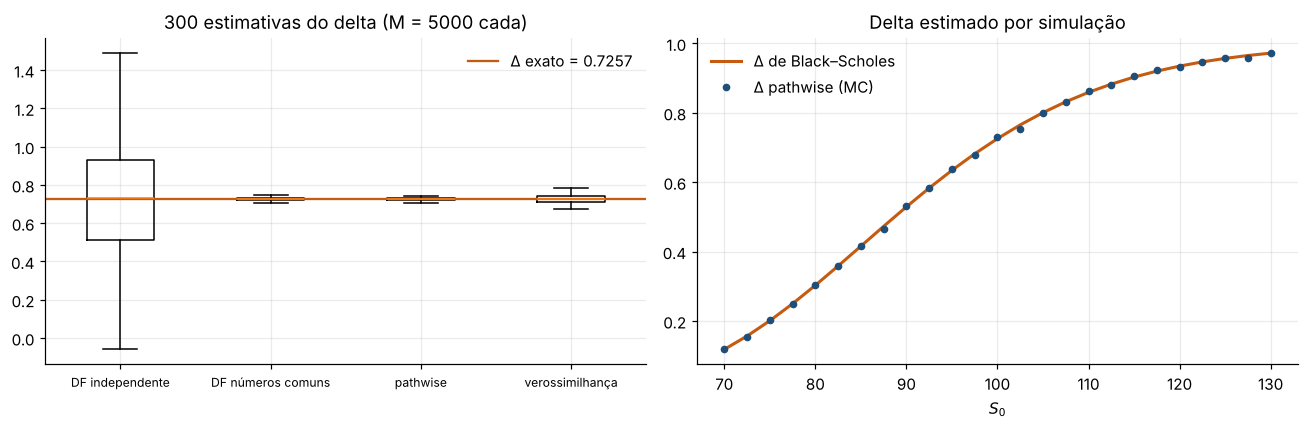

,média,desvio-padrão
DF independente,0.7320,0.3135
DF números comuns,0.7255,0.0076
pathwise,0.7256,0.0077
verossimilhança,0.7262,0.0223


In [14]:
def ST_de(Z, S_ini):
    return S_ini * np.exp((R - 0.5 * SIGMA**2) * T + SIGMA * np.sqrt(T) * Z)

def deltas_mc(M, h=0.5):
    Z1, Z2 = rng.standard_normal(M), rng.standard_normal(M)
    desc = np.exp(-R * T)
    fd_indep = desc * (np.maximum(ST_de(Z1, S0 + h) - K, 0).mean() - np.maximum(ST_de(Z2, S0 - h) - K, 0).mean()) / (2 * h)
    fd_crn   = desc * (np.maximum(ST_de(Z1, S0 + h) - K, 0) - np.maximum(ST_de(Z1, S0 - h) - K, 0)).mean() / (2 * h)
    ST = ST_de(Z1, S0)
    pathwise = desc * np.mean((ST > K) * ST / S0)
    lr       = desc * np.mean(np.maximum(ST - K, 0) * Z1 / (S0 * SIGMA * np.sqrt(T)))
    return fd_indep, fd_crn, pathwise, lr

arr = np.array([deltas_mc(5_000) for _ in range(300)])
nomes = ["DF independente", "DF números comuns", "pathwise", "verossimilhança"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
caixas(ax[0], arr, nomes, showfliers=False); ax[0].axhline(D0, color=LARANJA, label=f"Δ exato = {D0:.4f}")
ax[0].set_title("300 estimativas do delta (M = 5000 cada)"); ax[0].legend(); ax[0].tick_params(axis="x", labelsize=8)

S_grid = np.linspace(70, 130, 25)
d_pw = []
for s_ in S_grid:
    ST = ST_de(rng.standard_normal(20_000), s_)
    d_pw.append(np.exp(-R * T) * np.mean((ST > K) * ST / s_))
ax[1].plot(S_grid, bs_delta(S_grid, K, R, SIGMA, T), color=LARANJA, lw=2, label="Δ de Black–Scholes")
ax[1].plot(S_grid, d_pw, "o", color=AZUL, ms=4, label="Δ pathwise (MC)")
ax[1].set_xlabel("$S_0$"); ax[1].set_title("Delta estimado por simulação"); ax[1].legend()
plt.tight_layout(); plt.show()

pd.DataFrame({"média": arr.mean(0), "desvio-padrão": arr.std(0)}, index=nomes)

**O que observar.** Usar **números aleatórios comuns** reduz drasticamente a variância da diferença finita. Esse princípio (comparar alternativas **nos mesmos cenários**) será usado o tempo todo nas Partes 4 e 5. O estimador *pathwise* é o mais eficiente para a call e reproduz a curva de delta de Black–Scholes.

---
# Parte 4 — Monte Carlo para **medir risco**: VaR e Expected Shortfall

A partir daqui a pergunta muda. Não queremos mais "quanto vale?", e sim "**quanto posso perder** num horizonte $h$, com que probabilidade?". Por isso **simulamos sob a medida real $\mathbb P$** (drift $\mu$).

**Definições.** Seja $L$ a perda (positiva = prejuízo) no horizonte $h$ e $\alpha$ o nível de confiança (ex.: 99%):

$$
\mathrm{VaR}_\alpha=\text{quantil } \alpha \text{ de } L, \qquad
\mathrm{ES}_\alpha=\mathbb E\big[L\mid L\ge\mathrm{VaR}_\alpha\big].
$$

* **VaR 99%**: "em 99% dos dias a perda não passa deste valor". Não diz nada sobre **quanto** se perde no 1% restante.
* **ES 99%**: "**quando** a perda passa do VaR, em média ela é esta". O ES olha para dentro da cauda, é uma medida **coerente** (subaditiva) e é o padrão do regulador (Basileia/FRTB usa ES a 97,5%).

**Algoritmo geral (simulação completa / *full revaluation*):**

1. **Simular** os fatores de risco no horizonte $h$ sob $\mathbb P$.
2. **Reprecificar** a carteira inteira em cada cenário.
3. **Calcular** $L^{(i)}=V_0-V_h^{(i)}$.
4. **Ordenar** as perdas: o VaR é o quantil $\alpha$ e o ES é a média das perdas acima dele.

In [15]:
def var_es(perdas, alpha=0.99):
    # VaR = quantil alpha das perdas; ES = média das perdas >= VaR
    var = np.quantile(perdas, alpha)
    es = perdas[perdas >= var].mean()
    return var, es

def grafico_perdas(pnl, alpha=0.99, titulo="", ax=None, cor=AZUL, rotulo=None):
    # Histograma do P&L com VaR e ES marcados e a cauda sombreada.
    ax = ax or plt.gca()
    var, es = var_es(-pnl, alpha)
    cont, bordas, barras = ax.hist(pnl, bins=150, density=True, color=cor, alpha=0.55, label=rotulo)
    for b, e in zip(barras, bordas[:-1]):
        if e <= -var:
            b.set_color(VERMELHO)
    ax.axvline(-var, color=VERMELHO, lw=1.5, ls="--", label=f"−VaR {alpha:.0%} = {-var:.2f}")
    ax.axvline(-es, color="k", lw=1.5, ls=":", label=f"−ES {alpha:.0%} = {-es:.2f}")
    ax.set_xlabel("P&L"); ax.set_title(titulo); ax.legend(fontsize=8)
    return var, es

HORIZ = 10 / 252     # horizonte de 10 dias úteis (padrão regulatório)
print(f"horizonte h = {HORIZ:.4f} anos")

horizonte h = 0.0397 anos


## 4.1 O caso mais simples: uma ação

Carteira: **uma ação** comprada a $S_0=100$. Perda em 10 dias: $L=S_0-S_h$.

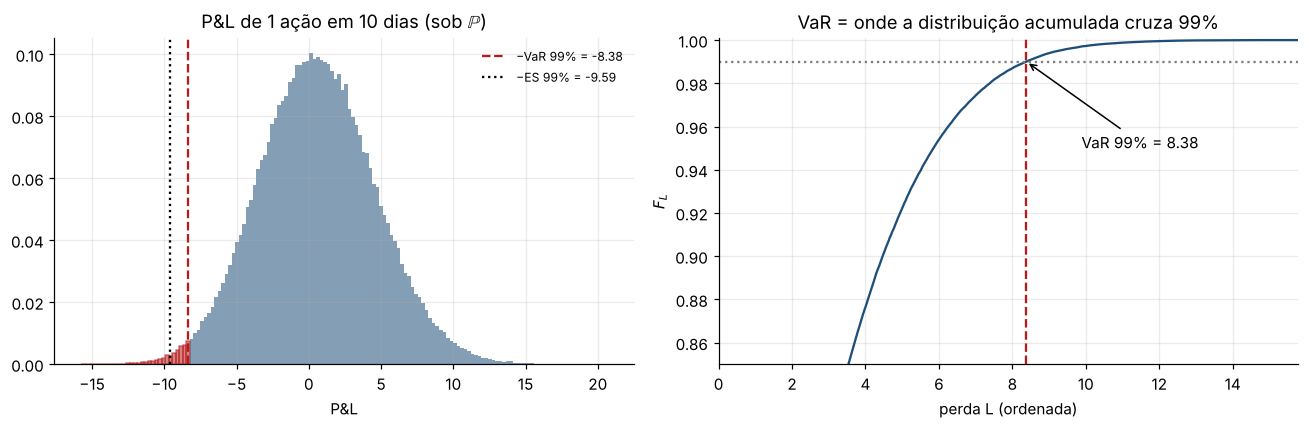

VaR 99% simulado = 8.380   VaR 99% exato (lognormal) = 8.380
ES  99% simulado = 9.593


In [16]:
M = 200_000
S_h = simular_ST(M, MU, T=HORIZ)                  # passo 1: fator de risco sob P no horizonte
pnl_acao = S_h - S0                               # passos 2-3: reprecificar (trivial) e P&L
perdas = -pnl_acao

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
var, es = grafico_perdas(pnl_acao, titulo="P&L de 1 ação em 10 dias (sob $\\mathbb{P}$)", ax=ax[0])

# passo 4 visualizado: a função de distribuição empírica das perdas e o quantil
pr = np.sort(perdas); F = np.arange(1, M + 1) / M
ax[1].plot(pr, F, color=AZUL)
ax[1].axhline(0.99, color=CINZA, ls=":"); ax[1].axvline(var, color=VERMELHO, ls="--")
ax[1].annotate(f"VaR 99% = {var:.2f}", xy=(var, 0.99), xytext=(var + 1.5, 0.95), arrowprops=dict(arrowstyle="->"))
ax[1].set_xlim(0, pr[-1]); ax[1].set_ylim(0.85, 1.001)
ax[1].set_xlabel("perda L (ordenada)"); ax[1].set_ylabel("$F_L$"); ax[1].set_title("VaR = onde a distribuição acumulada cruza 99%")
plt.tight_layout(); plt.show()

var_analitico = S0 - S0 * np.exp((MU - 0.5*SIGMA**2)*HORIZ + SIGMA*np.sqrt(HORIZ)*norm.ppf(0.01))
print(f"VaR 99% simulado = {var:.3f}   VaR 99% exato (lognormal) = {var_analitico:.3f}")
print(f"ES  99% simulado = {es:.3f}")

**O que observar.** Para uma ação, o VaR tem fórmula exata e o Monte Carlo a reproduz, o que serve como validação do código. A utilidade real do Monte Carlo aparece quando a carteira tem **opções**, cujo valor é **não linear** no fator de risco.

## 4.2 Uma carteira com opções: o livro de um *market maker*

Carteira: **vendido em 100 calls** ($K=100$, 1 ano). Este é exatamente o risco de quem vende opções e, por isso, precisa fazer hedge (Parte 5). Seguimos os quatro passos explicitamente:

,S_h (cenário),C_h (reprecificada),P&L do livro
cenário 1,97.1182,10.8943,237.5424
cenário 2,105.0652,16.7607,-349.1062
cenário 3,102.3041,14.6073,-133.7658
cenário 4,103.6022,15.6059,-233.6222
cenário 5,103.0859,15.2057,-193.5976
cenário 6,97.9980,11.4907,177.9018
cenário 7,95.2306,9.6650,360.4717
cenário 8,98.2018,11.6309,163.8813


Valor inicial do livro: -1326.97  |  VaR 99% = 780.85   ES 99% = 909.86


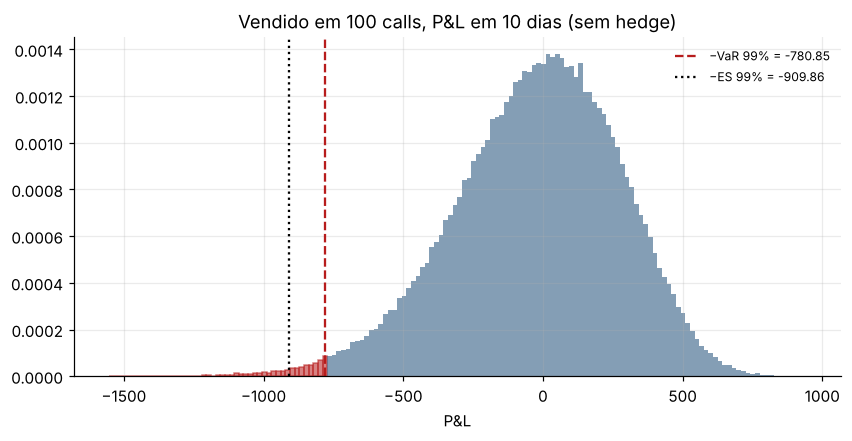

In [17]:
N_OPC = 100
M = 200_000
V0_livro = -N_OPC * C0                                        # valor inicial (passivo)

S_h   = simular_ST(M, MU, T=HORIZ)                            # PASSO 1: cenários do fator de risco sob P
C_h   = bs_preco(S_h, K, R, SIGMA, T - HORIZ)                 # PASSO 2: reprecificar a opção em cada cenário (prazo T-h)
V_h   = -N_OPC * C_h
pnl_livro = V_h - V0_livro                                    # PASSO 3: P&L
perdas_livro = -pnl_livro
var_l, es_l = var_es(perdas_livro)                            # PASSO 4: quantil e média da cauda

display(pd.DataFrame({"S_h (cenário)": S_h[:8], "C_h (reprecificada)": C_h[:8],
                      "P&L do livro": pnl_livro[:8]}, index=[f"cenário {i+1}" for i in range(8)]))
print(f"Valor inicial do livro: {V0_livro:.2f}  |  VaR 99% = {var_l:.2f}   ES 99% = {es_l:.2f}")

plt.figure(); grafico_perdas(pnl_livro, titulo="Vendido em 100 calls, P&L em 10 dias (sem hedge)"); plt.show()

**O que observar.** A distribuição é **assimétrica**: a cauda esquerda (perdas, quando a ação sobe) é mais longa que a direita. É a **convexidade (gama)** da opção trabalhando contra o vendedor. Uma medida que supõe normalidade erra exatamente aqui, como mostra a próxima seção.

## 4.3 Por que reprecificar tudo? Delta-normal × delta-gama × simulação completa

Métodos mais baratos aproximam o P&L por Taylor:

* **Delta-normal:** $\text{P\&L}\approx -N\,\Delta\,\delta S$ (linear, portanto normal).
* **Delta-gama:** $\text{P\&L}\approx -N\big(\Delta\,\delta S+\tfrac12\Gamma\,\delta S^2+\Theta\,h\big)$.
* **Simulação completa:** reprecifica com Black–Scholes em cada cenário (o "valor verdadeiro").

Usamos **os mesmos cenários** para os três métodos, então as diferenças vêm só da aproximação.

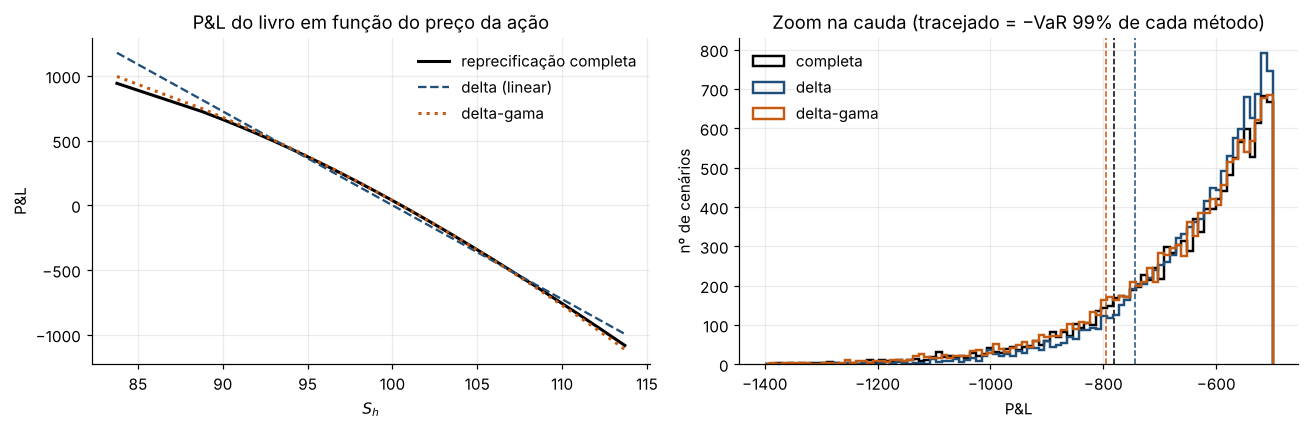

,VaR 99%,ES 99%,erro vs completa
delta-normal (simulado),744.2663,851.3348,-0.0469
delta-gama,795.1213,930.8124,0.0183
reprecificação completa,780.8507,909.8588,0.0000
delta-normal (fórmula z·|Δ|·S·σ·√h),672.6506,NaN,-0.1386


In [18]:
dS = S_h - S0
pnl_delta  = -N_OPC * (D0 * dS)
pnl_dgama  = -N_OPC * (D0 * dS + 0.5 * G0 * dS**2 + TH0 * HORIZ)
pnl_full   = pnl_livro

ordem = np.argsort(S_h)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sel = ordem[::200]
ax[0].plot(S_h[sel], pnl_full[sel], color="k", lw=2, label="reprecificação completa")
ax[0].plot(S_h[sel], pnl_delta[sel], color=AZUL, ls="--", label="delta (linear)")
ax[0].plot(S_h[sel], pnl_dgama[sel], color=LARANJA, ls=":", lw=2, label="delta-gama")
ax[0].set_xlabel("$S_h$"); ax[0].set_ylabel("P&L"); ax[0].set_title("P&L do livro em função do preço da ação"); ax[0].legend()

bins = np.linspace(-1400, -500, 90)
for p, c, n in [(pnl_full, "k", "completa"), (pnl_delta, AZUL, "delta"), (pnl_dgama, LARANJA, "delta-gama")]:
    ax[1].hist(p, bins=bins, histtype="step", lw=1.6, color=c, label=n)
    ax[1].axvline(-var_es(-p)[0], color=c, ls="--", lw=1)
ax[1].set_title("Zoom na cauda (tracejado = −VaR 99% de cada método)"); ax[1].set_xlabel("P&L"); ax[1].set_ylabel("nº de cenários"); ax[1].legend()
plt.tight_layout(); plt.show()

var_dn_analitico = norm.ppf(0.99) * N_OPC * D0 * S0 * SIGMA * np.sqrt(HORIZ)
linhas = {}
for nome, p in [("delta-normal (simulado)", pnl_delta), ("delta-gama", pnl_dgama), ("reprecificação completa", pnl_full)]:
    linhas[nome] = var_es(-p)
df = pd.DataFrame(linhas, index=["VaR 99%", "ES 99%"]).T
df.loc["delta-normal (fórmula z·|Δ|·S·σ·√h)"] = [var_dn_analitico, np.nan]
df["erro vs completa"] = df["VaR 99%"] / linhas["reprecificação completa"][0] - 1
df

**O que observar.**

* A curva preta (verdadeira) é **côncava** para o vendedor, porque ele está vendido em gama. A reta do delta fica **acima** dela nas duas pontas, ou seja, o método delta **subestima as perdas**.
* O delta-gama corrige a maior parte do erro, mas ainda é uma aproximação local que piora em choques grandes (crises, saltos).
* A fórmula analítica do delta-normal ($z_{99\%}\,|\Delta|\,S\,\sigma\sqrt h$, última linha) erra ainda mais, porque também ignora o drift e a assimetria lognormal do preço.
* **Conclusão para a apresentação:** para carteiras com opções, o VaR linear (delta-normal) subestima o risco de quem vende opções. O Monte Carlo com reprecificação completa captura a não linearidade, e é por isso que ele é usado.

## 4.4 O VaR também tem erro de Monte Carlo

O VaR estimado é uma variável aleatória. Quantos cenários são necessários? Repetimos o cálculo 200 vezes para vários tamanhos $M$:

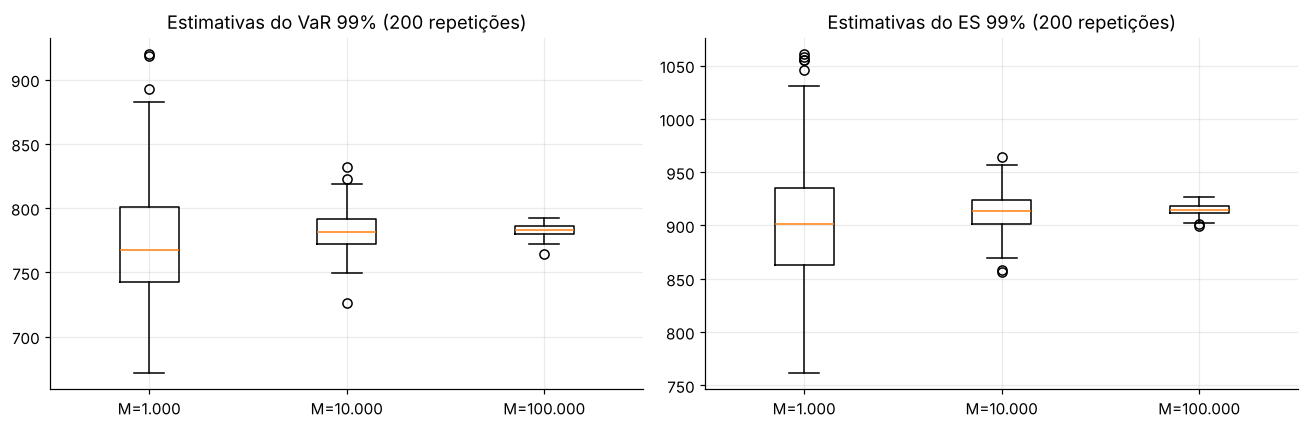

,VaR médio,dp do VaR,ES médio,dp do ES
M=1000,772.9946,45.3260,901.3934,59.2444
M=10000,781.1563,15.2180,912.9250,18.5377
M=100000,782.7815,4.4479,914.5791,5.2056


In [19]:
def var_es_livro(M):
    Sh = simular_ST(M, MU, T=HORIZ)
    pnl = -N_OPC * (bs_preco(Sh, K, R, SIGMA, T - HORIZ) - C0)
    return var_es(-pnl)

tamanhos = [1_000, 10_000, 100_000]
resultados = {m: np.array([var_es_livro(m) for _ in range(200)]) for m in tamanhos}

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
caixas(ax[0], [resultados[m][:, 0] for m in tamanhos], [f"M={m:,}".replace(",", ".") for m in tamanhos])
ax[0].set_title("Estimativas do VaR 99% (200 repetições)")
caixas(ax[1], [resultados[m][:, 1] for m in tamanhos], [f"M={m:,}".replace(",", ".") for m in tamanhos])
ax[1].set_title("Estimativas do ES 99% (200 repetições)")
plt.tight_layout(); plt.show()

pd.DataFrame({f"M={m}": {"VaR médio": r[:, 0].mean(), "dp do VaR": r[:, 0].std(),
                          "ES médio": r[:, 1].mean(), "dp do ES": r[:, 1].std()} for m, r in resultados.items()}).T

**O que observar.** Com $M=1000$, o VaR 99% é estimado a partir de apenas **10 cenários na cauda**, por isso a dispersão é grande. Estimar quantis extremos exige muitos cenários (ou técnicas como amostragem por importância). Ao reportar um VaR por simulação, informe também $M$ e a incerteza da estimativa.

## 4.5 Vários ativos: correlação via Cholesky e diversificação

Com $d$ ativos correlacionados, geramos normais independentes $\varepsilon\sim\mathcal N(0,I)$ e as transformamos com a **decomposição de Cholesky** da matriz de correlação $\Sigma=LL^\top$:

$$Z=L\,\varepsilon\ \Rightarrow\ \operatorname{Cov}(Z)=L\,I\,L^\top=\Sigma .$$

Carteira: uma ação A ($\sigma=25\%$) e uma ação B ($\sigma=30\%$), ambas a 100, com correlação $\rho$.

L =
 [[1.  0. ]
 [0.6 0.8]]
correlação amostral de Z: 0.6


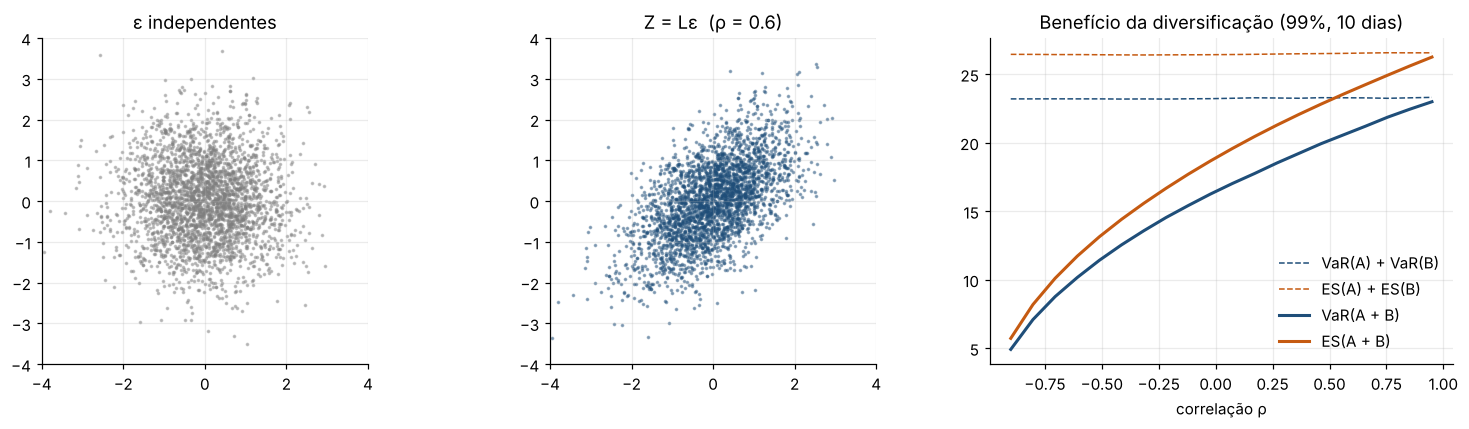

In [20]:
sig2 = np.array([0.25, 0.30]); mu2 = np.array([0.12, 0.15]); rho = 0.6
Corr = np.array([[1.0, rho], [rho, 1.0]])
L = np.linalg.cholesky(Corr)                         # Corr = L @ L.T
print("L =\n", L.round(4))

M = 200_000
eps = rng.standard_normal((M, 2))                    # independentes
Zc = eps @ L.T                                       # correlacionadas
print("correlação amostral de Z:", np.corrcoef(Zc.T)[0, 1].round(4))

def var_carteira(Zc):
    Sh = 100 * np.exp((mu2 - 0.5 * sig2**2) * HORIZ + sig2 * np.sqrt(HORIZ) * Zc)
    pA, pB = Sh[:, 0] - 100, Sh[:, 1] - 100
    return var_es(-pA), var_es(-pB), var_es(-(pA + pB))

rhos = np.linspace(-0.9, 0.95, 20)
v_soma, v_cart, e_soma, e_cart = [], [], [], []
for rr in rhos:
    Lr = np.linalg.cholesky(np.array([[1, rr], [rr, 1]]))
    (vA, eA), (vB, eB), (vP, eP) = var_carteira(eps @ Lr.T)       # MESMOS eps (números comuns)
    v_soma.append(vA + vB); v_cart.append(vP); e_soma.append(eA + eB); e_cart.append(eP)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].scatter(eps[:3000, 0], eps[:3000, 1], s=2, alpha=0.4, color=CINZA); ax[0].set_title("ε independentes")
ax[1].scatter(Zc[:3000, 0], Zc[:3000, 1], s=2, alpha=0.4, color=AZUL); ax[1].set_title(f"Z = Lε  (ρ = {rho})")
for a in ax[:2]: a.set_aspect("equal"); a.set_xlim(-4, 4); a.set_ylim(-4, 4)
ax[2].plot(rhos, v_soma, "--", color=AZUL, lw=1, label="VaR(A) + VaR(B)")
ax[2].plot(rhos, e_soma, "--", color=LARANJA, lw=1, label="ES(A) + ES(B)")
ax[2].plot(rhos, v_cart, color=AZUL, lw=2, label="VaR(A + B)")
ax[2].plot(rhos, e_cart, color=LARANJA, lw=2, label="ES(A + B)")
ax[2].set_xlabel("correlação ρ"); ax[2].set_title("Benefício da diversificação (99%, 10 dias)"); ax[2].legend()
plt.tight_layout(); plt.show()

**O que observar.** A distância entre cada linha tracejada (soma dos riscos individuais) e a linha cheia da mesma cor (risco da carteira) é o **benefício da diversificação**: ele é grande para correlação negativa e some quando $\rho\to1$. Em crises as correlações sobem, então **o risco da carteira sobe mesmo sem mudança nas volatilidades individuais**. Por isso testes de estresse com correlação elevada são parte padrão da gestão de risco.

## 4.6 Prevenção de risco com opções: ação + put protetora

A put protetora é o *hedge* estático mais simples: pagamos um prêmio hoje para limitar a perda. Comparamos vários strikes **nos mesmos cenários**. Note que a put também precisa ser **reprecificada** no horizonte (ela ainda tem $T-h$ de prazo), daí a necessidade de Monte Carlo com reprecificação.

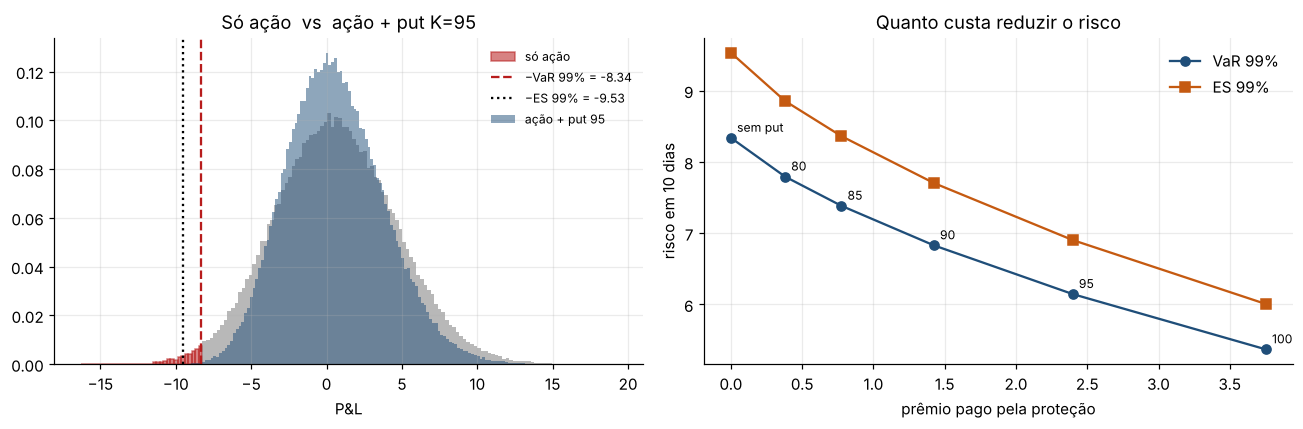

,prêmio,VaR 99%,ES 99%,P&L médio
strike,,,,
sem put,0.0000,8.3373,9.5308,0.6085
80,0.3797,7.7932,8.8541,0.6008
85,0.7747,7.3838,8.3613,0.5948
90,1.4239,6.8288,7.7030,0.5865
95,2.3982,6.1451,6.9029,0.5764
100,3.7534,5.3692,6.0058,0.5652


In [21]:
M = 200_000
S_h = simular_ST(M, MU, T=HORIZ)
pnl_sem = S_h - S0

linhas, pnls = [], {}
for Kp in [80, 85, 90, 95, 100]:
    premio = bs_preco(S0, Kp, R, SIGMA, T, "put")
    put_h = bs_preco(S_h, Kp, R, SIGMA, T - HORIZ, "put")          # reprecificação em cada cenário
    pnl = (S_h + put_h) - (S0 + premio)
    pnls[Kp] = pnl
    v, e = var_es(-pnl)
    linhas.append(dict(strike=Kp, prêmio=premio, **{"VaR 99%": v, "ES 99%": e, "P&L médio": pnl.mean()}))
v, e = var_es(-pnl_sem)
tab = pd.DataFrame([dict(strike="sem put", prêmio=0.0, **{"VaR 99%": v, "ES 99%": e, "P&L médio": pnl_sem.mean()})] + linhas).set_index("strike")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
grafico_perdas(pnl_sem, ax=ax[0], cor=CINZA, rotulo="só ação", titulo="Só ação  vs  ação + put K=95")
ax[0].hist(pnls[95], bins=150, density=True, alpha=0.5, color=AZUL, label="ação + put 95"); ax[0].legend(fontsize=8)
ax[1].plot(tab["prêmio"], tab["VaR 99%"], "o-", color=AZUL, label="VaR 99%")
ax[1].plot(tab["prêmio"], tab["ES 99%"], "s-", color=LARANJA, label="ES 99%")
for k_, row in tab.iterrows():
    ax[1].annotate(str(k_), (row["prêmio"], row["VaR 99%"]), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax[1].set_xlabel("prêmio pago pela proteção"); ax[1].set_ylabel("risco em 10 dias"); ax[1].set_title("Quanto custa reduzir o risco"); ax[1].legend()
plt.tight_layout(); plt.show()
tab

**O que observar.** Quanto mais alto o strike, menor o VaR/ES e **maior o prêmio** (e menor o P&L médio): proteção custa retorno esperado. O gráfico da direita é uma "fronteira" de decisão de proteção. Essa análise custo × risco é exatamente o que o Monte Carlo permite fazer de forma sistemática.

---
# Parte 5 — Monte Carlo para **testar o hedge dinâmico** (delta hedging)

Esta é a parte central do seu foco. Na teoria (Seção 8 da revisão), a carteira com $\Delta_t=\partial V/\partial S$ ações replica a opção **perfeitamente** se rebalanceada continuamente. Na prática rebalanceamos em datas discretas, o modelo pode estar errado e há custos. **O Monte Carlo mede quanto risco sobra.**

## 5.1 A carteira do vendedor, passo a passo

Um banco **vende** uma call e recebe o prêmio $C_0$. Para se proteger:

* **Em $t_0=0$:** recebe $C_0$, compra $\Delta_0$ ações e guarda o resto em caixa: $\text{Caixa}_0=C_0-\Delta_0S_0$ (pode ser negativo, ou seja, um empréstimo).
* **Em cada data $t_k$**, nesta ordem:
  1. o preço evolui: $S_{t_k}=S_{t_{k-1}}\exp\big((\mu-\tfrac12\sigma^2)\delta t+\sigma\sqrt{\delta t}Z_k\big)$ **(sob $\mathbb P$: é o mundo real)**;
  2. o caixa rende juros: $\text{Caixa}\leftarrow\text{Caixa}\cdot e^{r\delta t}$;
  3. calcula o novo delta $\Delta_k=N(d_1(S_{t_k},\tau_k))$;
  4. compra $(\Delta_k-\Delta_{k-1})$ ações, pagando com o caixa: $\text{Caixa}\leftarrow\text{Caixa}-(\Delta_k-\Delta_{k-1})S_{t_k}$.

  A carteira é **autofinanciável**: nenhum dinheiro entra ou sai depois de $t_0$.
* **No vencimento:** $\text{P\&L}=\underbrace{\text{Caixa}_T+\Delta_TS_T}_{\text{carteira de hedge}}-\underbrace{(S_T-K)^+}_{\text{o que devo ao cliente}}$.

Se o hedge fosse perfeito, o P&L seria **zero em todo cenário**.

Primeiro, uma única trajetória com **12 rebalanceamentos (mensais)**, com todos os números expostos:

In [22]:
def hedge_uma_trajetoria(n_reb, seed=7, sigma=SIGMA, mu=MU):
    # Versão DIDÁTICA (escalar, com laço explícito) do delta hedge de uma call vendida.
    rng_ = np.random.default_rng(seed)
    dt = T / n_reb
    S = S0
    premio = bs_preco(S0, K, R, sigma, T)
    delta = bs_delta(S0, K, R, sigma, T)
    caixa = premio - delta * S                            # recebe prêmio e compra delta ações
    linhas = [dict(passo=0, t=0.0, S=S, delta=delta, compra=delta, caixa=caixa,
                   carteira=caixa + delta * S, opcao=premio)]
    for i in range(1, n_reb + 1):
        S = S * np.exp((mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * rng_.standard_normal())  # 1. preço evolui (P)
        caixa = caixa * np.exp(R * dt)                                                              # 2. juros
        tau = T - i * dt
        if i < n_reb:
            novo_delta = float(bs_delta(S, K, R, sigma, tau)); opcao = float(bs_preco(S, K, R, sigma, tau))  # 3. novo delta
        else:
            novo_delta = 1.0 if S > K else 0.0; opcao = max(S - K, 0.0)    # no vencimento: entrega (ou não) a ação
        compra = novo_delta - delta
        caixa = caixa - compra * S                                         # 4. rebalanceia, pagando com o caixa
        delta = novo_delta
        linhas.append(dict(passo=i, t=i * dt, S=S, delta=delta, compra=compra, caixa=caixa,
                           carteira=caixa + delta * S, opcao=opcao))
    df = pd.DataFrame(linhas)
    df["erro de replicação"] = df["carteira"] - df["opcao"]
    return df

tab12 = hedge_uma_trajetoria(12)
display(tab12)
print(f"P&L final do vendedor (12 rebalanceamentos): {tab12['erro de replicação'].iloc[-1]:+.4f}")

,passo,t,S,delta,compra,caixa,carteira,opcao,erro de replicação
0,0,0.0000,100.0000,0.7257,0.7257,-59.3050,13.2697,13.2697,0.0000
1,1,0.0833,101.0964,0.7361,0.0104,-60.8491,13.5691,13.2867,0.2825
2,2,0.1667,103.9756,0.7767,0.0406,-65.5835,15.1793,14.6486,0.5307
3,3,0.2500,103.4576,0.7630,-0.0138,-64.7062,14.2282,13.4061,0.8221
4,4,0.3333,99.3428,0.6735,-0.0895,-56.3574,10.5473,9.5912,0.9561
5,5,0.4167,97.8230,0.6233,-0.0502,-51.9212,9.0521,7.7583,1.2939
6,6,0.5000,93.3859,0.4762,-0.1471,-38.6216,5.8520,4.4898,1.3622
7,7,0.5833,94.7315,0.4873,0.0110,-39.9891,6.1696,4.3352,1.8344
8,8,0.6667,103.4674,0.7394,0.2522,-66.4160,10.0916,8.7440,1.3476
9,9,0.7500,101.6639,0.6790,-0.0604,-60.8319,8.2023,6.3751,1.8272


P&L final do vendedor (12 rebalanceamentos): +3.2844


**Como ler a tabela.**

* `delta` é o número de ações em carteira **depois** do rebalanceamento.
* `compra` é o ajuste naquela data (positivo = comprou, negativo = vendeu). Note que **o hedge compra quando a ação sobe e vende quando ela cai**: o vendedor de opções "compra caro e vende barato", e essa é a origem do custo que o prêmio paga.
* `carteira` = caixa + ações; `opcao` = valor de Black–Scholes naquele instante.
* `erro de replicação` = carteira − opção: o quanto a carteira se afastou do que deveria valer. Se fosse sempre zero, o hedge seria perfeito.

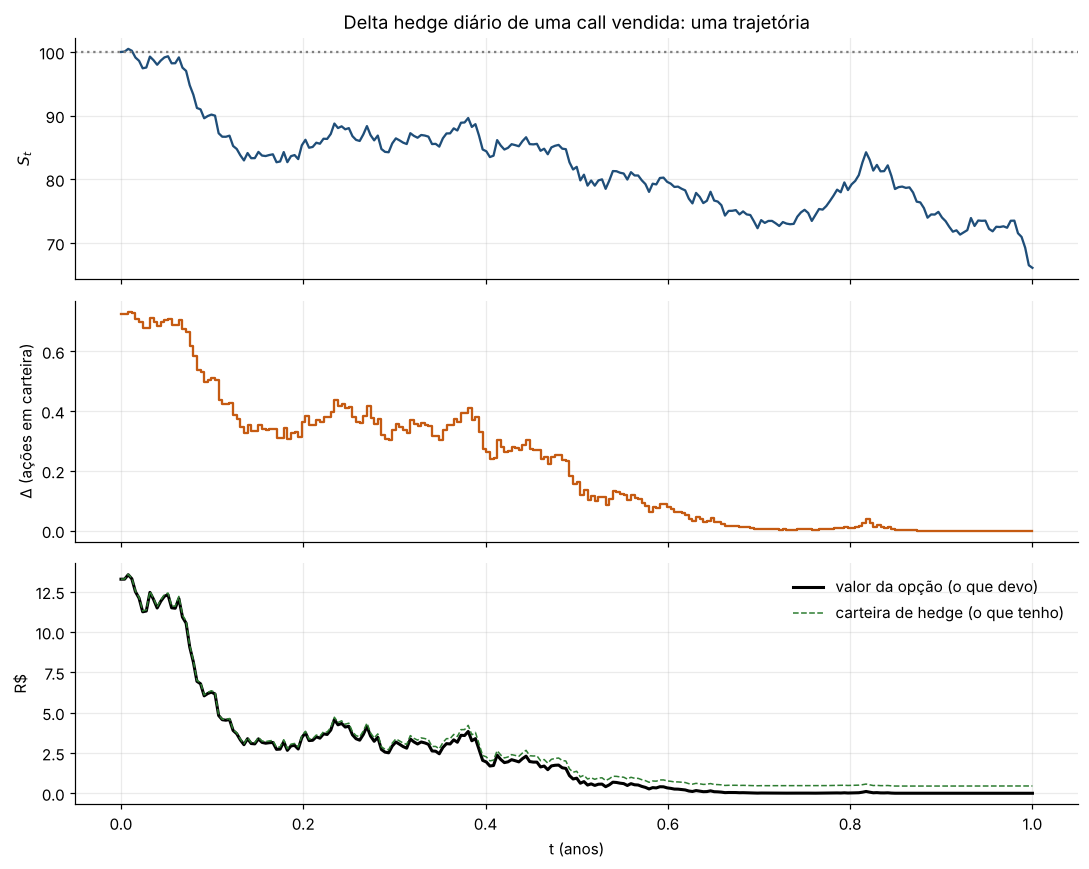

P&L final (252 rebalanceamentos): +0.4528


In [23]:
df = hedge_uma_trajetoria(252, seed=7)
fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax[0].plot(df.t, df.S, color=AZUL); ax[0].axhline(K, color=CINZA, ls=":"); ax[0].set_ylabel("$S_t$")
ax[0].set_title("Delta hedge diário de uma call vendida: uma trajetória")
ax[1].step(df.t, df.delta, where="post", color=LARANJA); ax[1].set_ylabel("Δ (ações em carteira)")
ax[2].plot(df.t, df.opcao, color="k", lw=2, label="valor da opção (o que devo)")
ax[2].plot(df.t, df.carteira, color=VERDE, lw=1, ls="--", label="carteira de hedge (o que tenho)")
ax[2].set_ylabel("R$"); ax[2].set_xlabel("t (anos)"); ax[2].legend()
plt.tight_layout(); plt.show()
print(f"P&L final (252 rebalanceamentos): {df['erro de replicação'].iloc[-1]:+.4f}")

**O que observar.** A carteira (verde tracejado) acompanha o valor da opção (preto) **sem precisar saber para onde a ação vai**. Isso é replicação: o banco não aposta na direção, só garante que terá o dinheiro para pagar o cliente.

## 5.2 Muitas trajetórias: a distribuição do P&L do hedge

Agora a versão **vetorizada**: os mesmos 4 passos, aplicados a 20 mil trajetórias ao mesmo tempo (cada variável vira um vetor com um elemento por trajetória). A função também registra, para uso nas próximas seções:

* a **aproximação teórica** do P&L, $\sum_k -\tfrac12\Gamma_kS_k^2\big[(\delta S_k/S_k)^2-\sigma^2\delta t\big]$;
* os **custos de transação**, opcionais;
* **saltos** no preço, opcionais, para o teste de estresse.

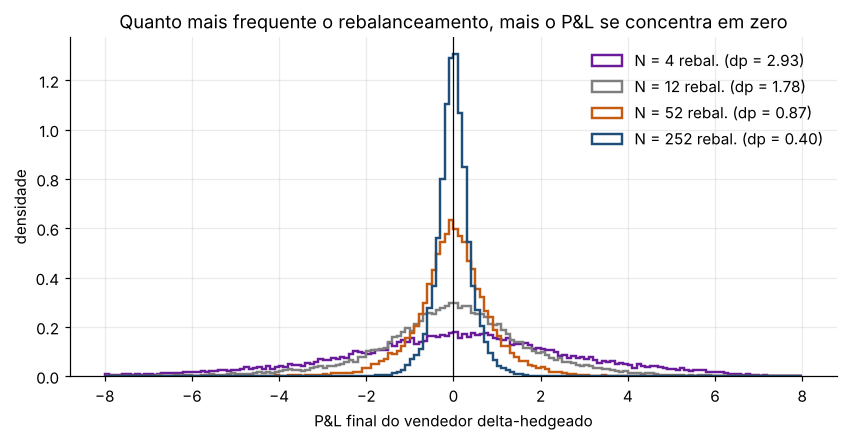

,média,desvio-padrão,VaR 95%,ES 95%,VaR 99%,ES 99%
N = 4,-0.0644,2.9328,5.1593,7.3259,8.6487,11.0126
N = 12,-0.0278,1.7751,3.0412,4.3544,5.0723,6.4948
N = 52,-0.0064,0.8748,1.4527,2.0842,2.4761,3.1825
N = 252,0.0065,0.3975,0.6289,0.8992,1.0562,1.2992


In [24]:
def simular_hedge(n_reb, n_traj=20_000, sigma_real=SIGMA, sigma_hedge=SIGMA, mu=MU,
                  custo=0.0, saltos=None, seed=None):
    # Simula o delta hedge de UMA call vendida em n_traj trajetórias sob P.
    #   sigma_real : volatilidade com que o mercado REALMENTE se move
    #   sigma_hedge: volatilidade usada para PRECIFICAR e calcular o delta (modelo do banco)
    #   custo      : custo proporcional de transação (ex.: 0.001 = 10 bps sobre o valor negociado)
    #   saltos     : dict(lam=intensidade anual, m=média do log-salto, s=dp do log-salto) ou None
    # Valores monetários são levados à data T (capitalizados à taxa r).
    g = np.random.default_rng(seed) if seed is not None else rng
    dt = T / n_reb
    S = np.full(n_traj, S0)
    premio = bs_preco(S0, K, R, sigma_hedge, T)
    delta = np.full(n_traj, bs_delta(S0, K, R, sigma_hedge, T))
    c0 = custo * np.abs(delta) * S
    caixa = premio - delta * S - c0                        # t0: recebe prêmio, compra delta, paga custo
    custos = c0 * np.exp(R * T)
    pnl_aprox = np.zeros(n_traj)

    if saltos:  # compensador: mantém o retorno esperado igual a mu mesmo com saltos
        kappa = np.exp(saltos["m"] + 0.5 * saltos["s"]**2) - 1
        drift_aj = mu - saltos["lam"] * kappa
    else:
        drift_aj = mu

    for i in range(1, n_reb + 1):
        gama = bs_gamma(S, K, R, sigma_hedge, T - (i - 1) * dt)
        Z = g.standard_normal(n_traj)
        S_novo = S * np.exp((drift_aj - 0.5 * sigma_real**2) * dt + sigma_real * np.sqrt(dt) * Z)   # 1. preço (P)
        if saltos:
            n_s = g.poisson(saltos["lam"] * dt, n_traj)
            S_novo *= np.exp(n_s * saltos["m"] + np.sqrt(n_s) * saltos["s"] * g.standard_normal(n_traj))
        retorno = S_novo / S - 1
        pnl_aprox += -0.5 * gama * S**2 * (retorno**2 - sigma_hedge**2 * dt) * np.exp(R * (T - i * dt))
        S = S_novo
        caixa *= np.exp(R * dt)                                                          # 2. juros
        tau = T - i * dt
        novo = bs_delta(S, K, R, sigma_hedge, tau) if i < n_reb else (S > K).astype(float)  # 3. novo delta
        c = custo * np.abs(novo - delta) * S
        caixa -= (novo - delta) * S + c                                                  # 4. rebalanceia
        custos += c * np.exp(R * (T - i * dt))
        delta = novo
    pnl = caixa + delta * S - np.maximum(S - K, 0)
    return dict(pnl=pnl, pnl_aprox=pnl_aprox, custos=custos, ST=S)

resultados_N = {N: simular_hedge(N) for N in [4, 12, 52, 252]}

fig, ax = plt.subplots()
for (N, rs), c in zip(resultados_N.items(), [ROXO, CINZA, LARANJA, AZUL]):
    ax.hist(rs["pnl"], bins=160, range=(-8, 8), density=True, histtype="step", lw=1.6, color=c,
            label=f"N = {N} rebal. (dp = {rs['pnl'].std():.2f})")
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("P&L final do vendedor delta-hedgeado"); ax.set_ylabel("densidade")
ax.set_title("Quanto mais frequente o rebalanceamento, mais o P&L se concentra em zero"); ax.legend()
plt.show()

def resumo(p):
    v95, e95 = var_es(-p, 0.95); v99, e99 = var_es(-p, 0.99)
    return {"média": p.mean(), "desvio-padrão": p.std(), "VaR 95%": v95, "ES 95%": e95, "VaR 99%": v99, "ES 99%": e99}
pd.DataFrame({f"N = {N}": resumo(rs["pnl"]) for N, rs in resultados_N.items()}).T

**O que observar.**

* A **média do P&L é ≈ 0** para qualquer $N$: o prêmio de Black–Scholes é exatamente o custo esperado do hedge.
* A **dispersão** cai com $N$: o risco que sobra é **erro de discretização**, não risco direcional.

## 5.3 A lei do $1/\sqrt N$

Derman e Kamal mostram que o desvio-padrão do erro de hedge é aproximadamente

$$
\text{dp(P\&L)}\approx\sqrt{\frac{\pi}{4}}\;\frac{\sigma\,\nu}{\sqrt N},
$$

onde $\nu$ é o vega da opção. Testamos essa fórmula:

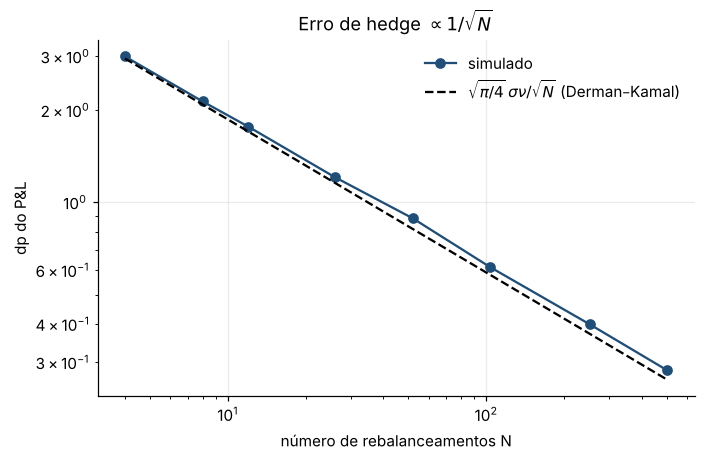

inclinação estimada: -0.488 (teoria: -0,5)


,dp simulado,dp teórico
N,,
4,2.9990,2.9531
8,2.1369,2.0882
12,1.7690,1.7050
26,1.2087,1.1583
52,0.8874,0.8190
104,0.6136,0.5792
252,0.3996,0.3721
504,0.2823,0.2631


In [25]:
Ns = np.array([4, 8, 12, 26, 52, 104, 252, 504])
dps = np.array([simular_hedge(N, n_traj=10_000)["pnl"].std() for N in Ns])
teorico = np.sqrt(np.pi / 4) * SIGMA * V0 / np.sqrt(Ns)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.loglog(Ns, dps, "o-", color=AZUL, label="simulado")
ax.loglog(Ns, teorico, "k--", label="$\\sqrt{\\pi/4}\\,\\sigma\\nu/\\sqrt{N}$ (Derman–Kamal)")
ax.set_xlabel("número de rebalanceamentos N"); ax.set_ylabel("dp do P&L"); ax.set_title("Erro de hedge $\\propto 1/\\sqrt{N}$"); ax.legend()
plt.show()
print("inclinação estimada:", np.polyfit(np.log(Ns), np.log(dps), 1)[0].round(3), "(teoria: -0,5)")
pd.DataFrame({"N": Ns, "dp simulado": dps, "dp teórico": teorico}).set_index("N")

**O que observar.** Simulação e fórmula concordam, e a inclinação é $-1/2$. É o mesmo $1/\sqrt{\cdot}$ do erro do Monte Carlo e do passeio aleatório: **as três coisas vêm do TCL / variação quadrática**. Para reduzir o erro à metade é preciso rebalancear **4 vezes** mais (e pagar 4 vezes mais operações; veja a Seção 5.7).

## 5.4 *De onde* vem o erro? A fórmula $\tfrac12\Gamma S^2[(\delta S/S)^2-\sigma^2\delta t]$

Esta é a equação mais importante do hedging. Em cada intervalo, por Taylor e pela EDP de Black–Scholes, o P&L do vendedor hedgeado é

$$
\delta\Pi_k\approx-\tfrac12\Gamma_kS_k^2\Big[\underbrace{\Big(\frac{\delta S_k}{S_k}\Big)^2}_{\text{variância realizada}}-\underbrace{\sigma^2\delta t}_{\text{variância implícita}}\Big].
$$

* O **delta elimina o risco de primeira ordem** (a direção do mercado).
* O que sobra é uma **aposta em volatilidade**: o vendedor perde quando a ação se move **mais** que o previsto e ganha quando se move **menos**, ponderado pelo *dollar gamma* $\tfrac12\Gamma S^2$.

A função `simular_hedge` acumula essa aproximação em `pnl_aprox`. Se a teoria estiver certa, o P&L real e o aproximado devem ficar sobre a reta de 45°.

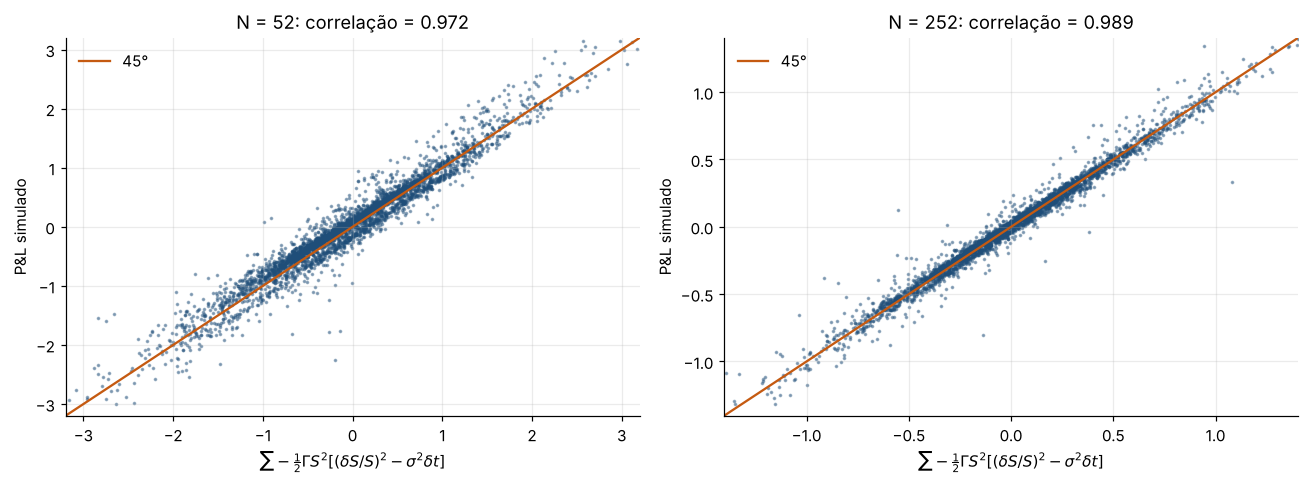

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, N in zip(ax, [52, 252]):
    rs = resultados_N[N]
    a.scatter(rs["pnl_aprox"][:4000], rs["pnl"][:4000], s=2, alpha=0.4, color=AZUL)
    lim = np.percentile(np.abs(rs["pnl"]), 99.5)
    a.plot([-lim, lim], [-lim, lim], color=LARANJA, lw=1.5, label="45°")
    corr = np.corrcoef(rs["pnl_aprox"], rs["pnl"])[0, 1]
    a.set_xlim(-lim, lim); a.set_ylim(-lim, lim)
    a.set_xlabel("$\\sum -\\frac{1}{2}\\Gamma S^2[(\\delta S/S)^2-\\sigma^2\\delta t]$")
    a.set_ylabel("P&L simulado"); a.set_title(f"N = {N}: correlação = {corr:.3f}"); a.legend()
plt.tight_layout(); plt.show()

**O que observar.** Os pontos caem sobre a reta: **o erro do hedge é inteiramente explicado pela diferença entre a volatilidade realizada e a implícita, ponderada pelo gama**. Este é provavelmente o gráfico mais convincente para mostrar ao orientador que você entende o mecanismo, e não só a fórmula.

## 5.5 O drift $\mu$ não importa (com hedge)

Na derivação da EDP o termo $\mu$ se cancela. Testamos isso: repetimos o hedge com drifts reais muito diferentes. Para comparação, mostramos também o vendedor **sem hedge** (que recebeu o prêmio e ficou parado).

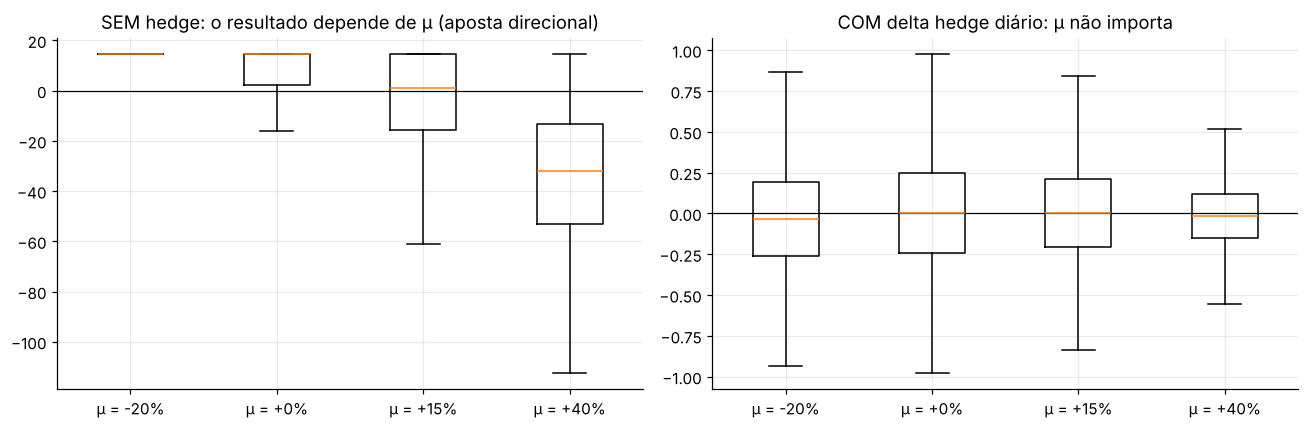

,P&L médio sem hedge,P&L médio com hedge,dp com hedge
μ = -20%,13.1926,-0.0344,0.3855
μ = +0%,6.6419,-0.0045,0.4346
μ = +15%,-4.4340,0.0023,0.3995
μ = +40%,-34.8783,-0.0219,0.2633


In [27]:
mus = [-0.20, 0.0, 0.15, 0.40]
com_hedge, sem_hedge = [], []
for m in mus:
    rs = simular_hedge(252, n_traj=10_000, mu=m)
    com_hedge.append(rs["pnl"])
    sem_hedge.append(C0 * np.exp(R * T) - np.maximum(rs["ST"] - K, 0))   # mesmas trajetórias, sem hedge

rot = [f"μ = {m:+.0%}" for m in mus]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
caixas(ax[0], sem_hedge, rot, showfliers=False); ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_title("SEM hedge: o resultado depende de μ (aposta direcional)")
caixas(ax[1], com_hedge, rot, showfliers=False); ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_title("COM delta hedge diário: μ não importa")
plt.tight_layout(); plt.show()
pd.DataFrame({"P&L médio sem hedge": [p.mean() for p in sem_hedge],
              "P&L médio com hedge": [p.mean() for p in com_hedge],
              "dp com hedge": [p.std() for p in com_hedge]}, index=rot)

**O que observar.** Sem hedge, o lucro máximo do vendedor é o prêmio capitalizado ($\approx 14{,}7$, o "teto" dos boxplots da esquerda), enquanto a perda é ilimitada. Ele perde muito se a ação sobe muito ($\mu$ alto) e ganha se ela cai. Com hedge, a distribuição é praticamente a mesma para qualquer $\mu$. **É por isso que o preço de Black–Scholes não depende do retorno esperado da ação**, e essa é a resposta à pergunta clássica "por que $\mu$ não aparece na fórmula?".

## 5.6 Risco de modelo: e se a volatilidade estiver errada?

Agora o ponto mais importante para gestão de risco. O banco precifica e calcula o delta com $\sigma_h=20\%$, mas o mercado realiza $\sigma_r$ diferente. A teoria (Seção 9.3 da revisão) diz que o P&L esperado do vendedor é aproximadamente a diferença de preços:

$$
\mathbb E[\text{P\&L}]\approx e^{rT}\big[C(\sigma_h)-C(\sigma_r)\big].
$$

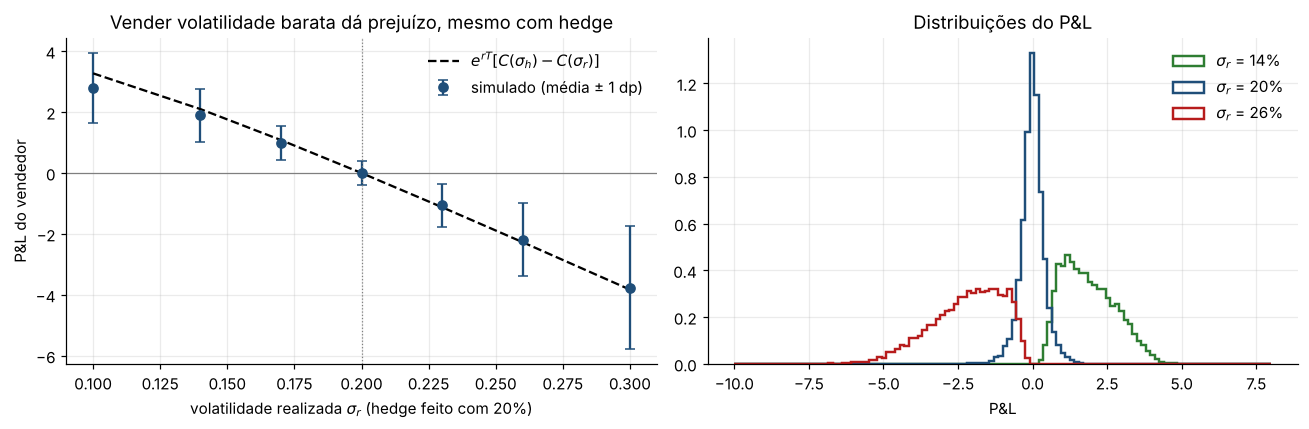

,P&L médio simulado,teoria,dp
σ realizada,,,
0.1000,2.8033,3.2730,1.1466
0.1400,1.8919,2.0986,0.8781
0.1700,0.9925,1.0816,0.5668
0.2000,0.0002,0.0000,0.4024
0.2300,-1.0609,-1.1221,0.6955
0.2600,-2.1867,-2.2707,1.2009
0.3000,-3.7613,-3.8288,2.0209


In [28]:
sig_reais = np.array([0.10, 0.14, 0.17, 0.20, 0.23, 0.26, 0.30])
medias, dps_v, dist = [], [], {}
for sr in sig_reais:
    p = simular_hedge(252, n_traj=10_000, sigma_real=sr, sigma_hedge=0.20)["pnl"]
    medias.append(p.mean()); dps_v.append(p.std()); dist[sr] = p
teoria = np.exp(R * T) * (bs_preco(S0, K, R, 0.20, T) - bs_preco(S0, K, R, sig_reais, T))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].errorbar(sig_reais, medias, yerr=dps_v, fmt="o", color=AZUL, capsize=3, label="simulado (média ± 1 dp)")
ax[0].plot(sig_reais, teoria, "k--", label="$e^{rT}[C(\\sigma_h)-C(\\sigma_r)]$")
ax[0].axhline(0, color=CINZA, lw=0.8); ax[0].axvline(0.20, color=CINZA, ls=":", lw=0.8)
ax[0].set_xlabel("volatilidade realizada $\\sigma_r$ (hedge feito com 20%)"); ax[0].set_ylabel("P&L do vendedor")
ax[0].set_title("Vender volatilidade barata dá prejuízo, mesmo com hedge"); ax[0].legend()
for sr, c in [(0.14, VERDE), (0.20, AZUL), (0.26, VERMELHO)]:
    ax[1].hist(dist[sr], bins=120, range=(-10, 8), density=True, histtype="step", lw=1.6, color=c, label=f"$\\sigma_r$ = {sr:.0%}")
ax[1].set_xlabel("P&L"); ax[1].set_title("Distribuições do P&L"); ax[1].legend()
plt.tight_layout(); plt.show()
pd.DataFrame({"σ realizada": sig_reais, "P&L médio simulado": medias, "teoria": teoria, "dp": dps_v}).set_index("σ realizada")

**O que observar.**

* O hedge continua eliminando o risco **direcional**, mas o vendedor que precificou com volatilidade **abaixo** da realizada tem **prejuízo sistemático** (a média se desloca). Esse é o **risco de volatilidade / risco de modelo**, e nenhum delta o elimina.
* Isso fecha o raciocínio da Seção 5.4: P&L ≈ gama × (variância realizada − implícita).
* A pequena diferença entre simulação e fórmula (maior para $\sigma_r$ baixo) existe porque a fórmula é exata apenas sob $\mathbb Q$; aqui as trajetórias são simuladas sob $\mathbb P$ com $\mu\neq r$, e o P&L depende de por onde a trajetória passou enquanto o gama era alto.
* Na prática, é por isso que *desks* de opções monitoram o **vega** e fazem testes de estresse de volatilidade.

## 5.7 Custos de transação: o *trade-off* do rebalanceamento

Rebalancear mais reduz o erro de hedge ($\propto 1/\sqrt N$), mas **cada operação custa**. O volume total negociado $\sum|\Delta_k-\Delta_{k-1}|S_k$ cresce como $\sqrt N$ (o delta herda a variação "browniana" do preço). Simulamos com custo de 0,1% (10 bps) sobre o valor negociado:

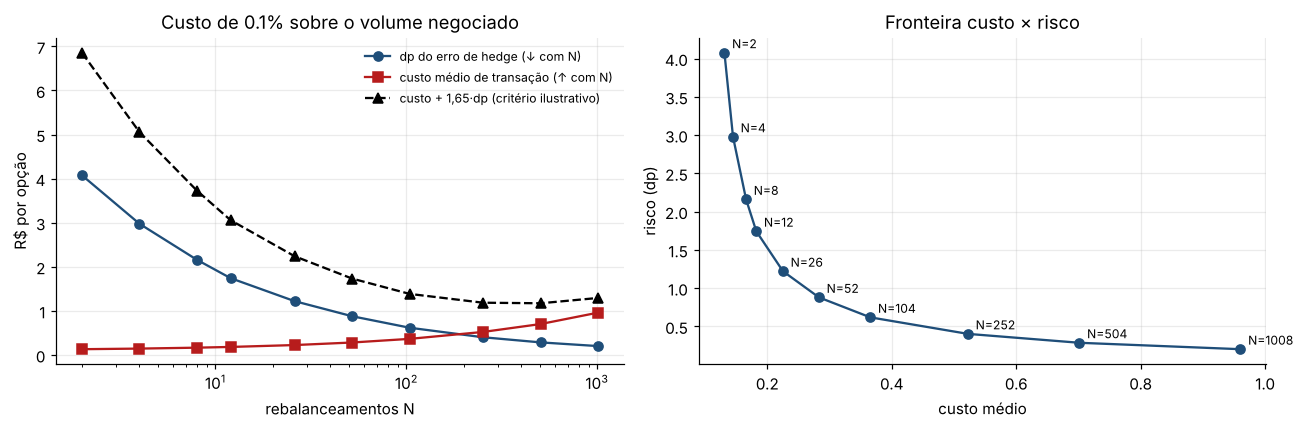

pelo critério ilustrativo (custo + 1,65·dp), a frequência preferida é N ≈ 504


In [29]:
CUSTO = 0.001
Ns_c = np.array([2, 4, 8, 12, 26, 52, 104, 252, 504, 1008])
custo_medio, dp_hedge, dp_total = [], [], []
for N in Ns_c:
    rs = simular_hedge(N, n_traj=8_000, custo=CUSTO)
    custo_medio.append(rs["custos"].mean())
    dp_hedge.append((rs["pnl"] + rs["custos"]).std())   # erro de hedge sem o efeito do custo
    dp_total.append(rs["pnl"].std())

custo_medio, dp_hedge = np.array(custo_medio), np.array(dp_hedge)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogx(Ns_c, dp_hedge, "o-", color=AZUL, label="dp do erro de hedge (↓ com N)")
ax[0].semilogx(Ns_c, custo_medio, "s-", color=VERMELHO, label="custo médio de transação (↑ com N)")
ax[0].semilogx(Ns_c, custo_medio + 1.65 * dp_hedge, "^--", color="k", label="custo + 1,65·dp (critério ilustrativo)")
ax[0].set_xlabel("rebalanceamentos N"); ax[0].set_ylabel("R$ por opção"); ax[0].set_title(f"Custo de {CUSTO:.1%} sobre o volume negociado"); ax[0].legend(fontsize=8)
ax[1].plot(custo_medio, dp_hedge, "o-", color=AZUL)
for N, x_, y_ in zip(Ns_c, custo_medio, dp_hedge):
    ax[1].annotate(f"N={N}", (x_, y_), textcoords="offset points", xytext=(5, 3), fontsize=8)
ax[1].set_xlabel("custo médio"); ax[1].set_ylabel("risco (dp)"); ax[1].set_title("Fronteira custo × risco")
plt.tight_layout(); plt.show()
N_otimo = Ns_c[np.argmin(custo_medio + 1.65 * dp_hedge)]
print(f"pelo critério ilustrativo (custo + 1,65·dp), a frequência preferida é N ≈ {N_otimo}")

**O que observar.** Existe uma **frequência ótima** de rebalanceamento: rebalancear continuamente seria infinitamente caro (o browniano tem variação total infinita, Seção 4 da revisão). A escolha depende da aversão a risco do banco (o critério "custo + 1,65·dp" acima é apenas ilustrativo). Leland (1985) incorpora esse efeito ajustando a volatilidade usada no hedge.

## 5.8 Comparação final: sem hedge × hedge estático × hedge dinâmico

Sobre **as mesmas trajetórias**, comparamos três estratégias do vendedor:

* **sem hedge:** recebe o prêmio e espera;
* **estático:** compra $\Delta_0$ ações em $t_0$ e nunca mais mexe;
* **dinâmico diário:** delta hedge com 252 rebalanceamentos.

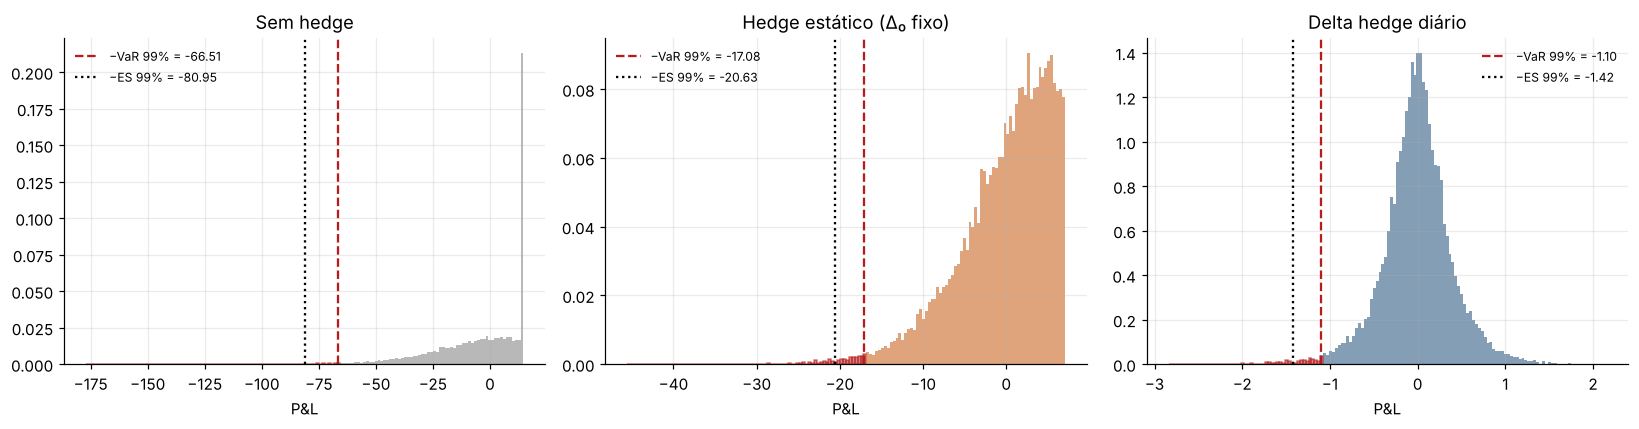

,média,desvio-padrão,VaR 95%,ES 95%,VaR 99%,ES 99%,redução do ES 99% vs sem hedge
sem hedge,-4.4945,20.0108,43.3069,57.5727,66.5101,80.9542,0.0000
estático,-0.2327,5.4947,10.7511,14.6395,17.0761,20.6281,0.7452
dinâmico diário,-0.0036,0.3991,0.6608,0.9472,1.1016,1.4195,0.9825


In [30]:
rs = simular_hedge(252, n_traj=20_000, seed=11)
ST = rs["ST"]
pnl_sem = C0 * np.exp(R * T) - np.maximum(ST - K, 0)
pnl_est = (C0 - D0 * S0) * np.exp(R * T) + D0 * ST - np.maximum(ST - K, 0)
pnl_din = rs["pnl"]

fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for a, p, tit, c in zip(ax, [pnl_sem, pnl_est, pnl_din],
                        ["Sem hedge", "Hedge estático (Δ₀ fixo)", "Delta hedge diário"], [CINZA, LARANJA, AZUL]):
    grafico_perdas(p, ax=a, titulo=tit, cor=c)
plt.tight_layout(); plt.show()

comp = pd.DataFrame({"sem hedge": resumo(pnl_sem), "estático": resumo(pnl_est), "dinâmico diário": resumo(pnl_din)}).T
comp["redução do ES 99% vs sem hedge"] = 1 - comp["ES 99%"] / comp.loc["sem hedge", "ES 99%"]
comp

**O que observar.** Atenção às escalas horizontais diferentes. O hedge dinâmico reduz o ES 99% em mais de 95%: **o risco de perder dezenas de reais por opção vira um risco de centavos**. O hedge estático ajuda pouco, porque o delta muda ao longo do tempo e a proteção "envelhece".

## 5.9 Teste de estresse: saltos (o que o delta **não** consegue proteger)

O modelo de Black–Scholes supõe trajetórias contínuas. E se o preço **saltar** (anúncio de resultado, crise)? Simulamos o modelo de Merton: em média 1 salto por ano, com log-salto $\sim\mathcal N(-10\%,\,5\%)$. O banco continua usando o delta de Black–Scholes com 20%.

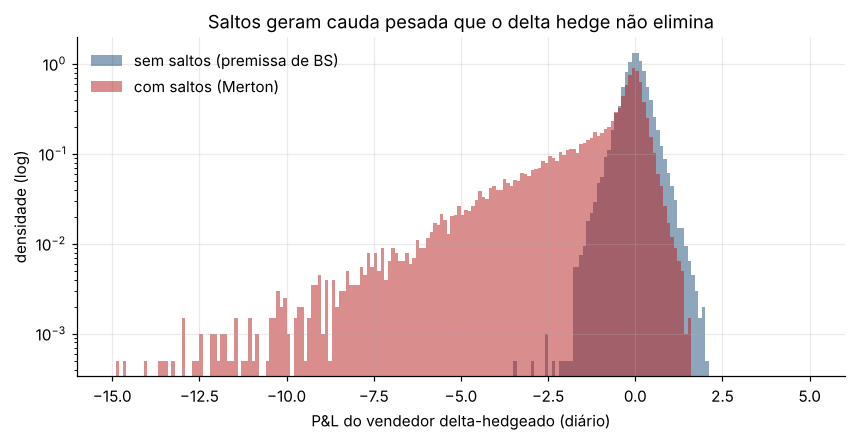

,média,desvio-padrão,VaR 95%,ES 95%,VaR 99%,ES 99%
sem saltos,-0.0004,0.3985,0.6445,0.9302,1.1094,1.3793
com saltos,-1.0657,1.7400,4.5711,6.4452,7.6381,9.5384


In [31]:
SALTOS = dict(lam=1.0, m=-0.10, s=0.05)
p_continuo = simular_hedge(252, n_traj=20_000, seed=21)["pnl"]
p_saltos   = simular_hedge(252, n_traj=20_000, saltos=SALTOS, seed=21)["pnl"]

fig, ax = plt.subplots()
ax.hist(p_continuo, bins=200, range=(-15, 5), density=True, alpha=0.5, color=AZUL, label="sem saltos (premissa de BS)")
ax.hist(p_saltos, bins=200, range=(-15, 5), density=True, alpha=0.5, color=VERMELHO, label="com saltos (Merton)")
ax.set_yscale("log"); ax.set_xlabel("P&L do vendedor delta-hedgeado (diário)"); ax.set_ylabel("densidade (log)")
ax.set_title("Saltos geram cauda pesada que o delta hedge não elimina"); ax.legend()
plt.show()
pd.DataFrame({"sem saltos": resumo(p_continuo), "com saltos": resumo(p_saltos)}).T

**O que observar.** Com saltos o **mercado é incompleto**: entre duas datas de rebalanceamento o preço "pula" e o delta não tem tempo de se ajustar. A cauda esquerda engrossa (escala log!) e o ES aumenta várias vezes, **mesmo com hedge diário**. Este é o tipo de risco que só aparece num teste de estresse por simulação, e é a principal motivação para:
* hedge com outras opções (delta-gama), que protege contra movimentos grandes;
* modelos com saltos e volatilidade estocástica;
* limites de risco baseados em ES, e não só em VaR.

---
# Parte 6 — Síntese

## Onde está o risco e como o Monte Carlo o mede

| Fonte de risco | Quem elimina | O que sobra | Como medimos aqui | Seção |
|---|---|---|---|---|
| Direção do mercado ($\delta S$) | **delta hedge** | nada (1ª ordem) | P&L médio ≈ 0 para qualquer $\mu$ | 5.5 |
| Rebalanceamento discreto | aumentar $N$ | dp $\propto 1/\sqrt N$ | lei de Derman–Kamal | 5.3 |
| Volatilidade realizada ≠ implícita | hedge de **vega** com outras opções | $\tfrac12\Gamma S^2(\sigma_r^2-\sigma_h^2)$ | P&L sistemático | 5.4, 5.6 |
| Custos de transação | frequência ótima | trade-off custo × risco | fronteira | 5.7 |
| Saltos | hedge de **gama** / opções | cauda pesada | estresse com Merton | 5.9 |
| Não linearidade no VaR | reprecificação completa | erro do delta-normal | 3 métodos nos mesmos cenários | 4.3 |
| Erro do próprio Monte Carlo | aumentar $M$, redução de variância | $\propto 1/\sqrt M$ | IC, cobertura, dispersão do VaR | 3.3–3.5, 4.4 |

## Roteiro sugerido para a reunião com o orientador

1. **Validação** (Seção 1.2 e 3.3): "a simulação reproduz a lognormal e o preço de Black–Scholes, com erro $\propto 1/\sqrt M$."
2. **$\mathbb P$ versus $\mathbb Q$** (Seção 1.2): "apreço sob $\mathbb Q$, meço risco sob $\mathbb P$."
3. **VaR com opções** (Seção 4.3): "o delta-normal subestima o risco de quem vende opções; por isso reprecifico tudo."
4. **Hedge funciona e $\mu$ não importa** (Seções 5.2 e 5.5).
5. **Mecanismo do erro** (Seção 5.4): o gráfico de 45° entre P&L e $\tfrac12\Gamma S^2[(\delta S/S)^2-\sigma^2\delta t]$.
6. **Limites** (Seções 5.6–5.9): volatilidade errada, custos e saltos, ou seja, o que motiva modelos além de Black–Scholes.

## Extensões naturais (possíveis temas de dissertação)

* Hedge delta-gama e delta-vega com uma segunda opção, comparado por ES.
* Volatilidade estocástica (Heston) com Euler + *full truncation*: hedge de BS num mundo de Heston.
* Quase-Monte Carlo (Sobol) e amostragem por importância para quantis extremos (VaR 99,9%).
* Hedge ótimo sob custos (Leland, Whalley–Wilmott) ou *deep hedging*.
* *Backtesting* do VaR com dados reais (teste de Kupiec).